# DMDP with SAC: the code

This notebook shows the complete code of the SAC learner of the experiments in
*Dissimilarity-Based Markov Decision Processes for Stabilizing State Distributions*
(Section 5.1 and Appendix E of the paper): the target, the configuration, the environment wrappers, the soft actor-critic learner and its Lagrangian variant, the evaluation, and the metrics.
`DMDP_PPO.ipynb` shows the PPO learner in the same way.

**How the notebook is made.** `build_code_notebooks.py` copies the code cells without change from the package `dmdp_sg/`, one section per module, so the notebook shows the code that produced the stored results; `tests/test_code_notebooks.py` checks this.
The notebook does not import `dmdp_sg`: its cells define everything in one namespace, in the order of the dependencies between the modules.
Two things differ from the files of the package: the imports between the modules are commented out, because their names are defined in the cells above, and `load_policy` shows the branch for the SAC learner only.
SAC takes a few helpers from the modules of the PPO learner; Section 5 shows them.

**Methods trained with SAC.** Every method maximizes the return of its training reward with the same learner, and the methods differ only in the policy input, the training reward, the reward critics, and the cost constraint.

| Method | Policy input | Training reward | Reward critics | Cost constraint |
|---|---|---|---|---|
| SAC | $\mathbf{o}_t$ | $r^{\mathsf{b}}_t$ | expected return | no |
| SAC-Lag | $\mathbf{o}_t$ | $r^{\mathsf{b}}_t-\lambda c_t$ | expected return | yes |
| Distributional SAC (`Dist-SAC`) | $\mathbf{o}_t$ | $r^{\mathsf{b}}_t$ | 32 quantiles of the return | no |
| Distributional SAC-Lag (`Dist-SAC-Lag`) | $\mathbf{o}_t$ | $r^{\mathsf{b}}_t-\lambda c_t$ | 32 quantiles of the return | yes |
| Implicit DMDP (SAC) (`Implicit-SAC`) | $\hat\omega_t$ and $\mathbf{o}_t$ | $r^{\mathsf{b}}_t$ | 32 quantiles of the return | no |
| Implicit DMDP-Lag (SAC) (`Implicit-SAC-Lag`) | $\hat\omega_t$ and $\mathbf{o}_t$ | $r^{\mathsf{b}}_t-\lambda c_t$ | 32 quantiles of the return | yes |
| DMDP (SAC) (`DMDP`) | $\hat\omega_t$ and $\mathbf{o}_t$ | $r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t$ | expected return | no |
| DMDP-Lag (SAC) (`DMDP-Lag`) | $\hat\omega_t$ and $\mathbf{o}_t$ | $r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t-\lambda c_t$ | expected return | yes |

Here $r^{\mathsf{b}}_t=v_t-0.1\|\mathbf{a}_t\|^2$ is the benchmark reward, $c_t=\mathbf{1}[v_t>v_{\mathsf{lim}}]$ the safety cost, $\hat\omega_t$ the window statistics of the noisy readings, $\mathbb{D}_t$ the window dissimilarity to the target, and $r_{t\mathbb{D}}$ the threshold reward.
The docstring of `config.py` lists the notation.

**Sections.** 1 Setup · 2 Target distributions · 3 Configuration · 4 Environment wrappers · 5 Helpers of the PPO learner · 6 SAC learner · 7 Evaluation rollouts · 8 Metrics · 9 Analysis · 10 Examples and checks · 11 Stored results.

**Running it.** Run the cells from top to bottom in the environment of `environment.yml`; the whole notebook takes less than a minute.
Sections 1 to 9 define the code, Section 10 calls it with small settings, and Section 11 reads the stored runs in `results/sac`.
The full runs of the paper are launched with `run_all.py` (see the README).

## 1 Setup

The first cell postpones the evaluation of annotations, as every module of the package does, and registers the Safety-Gymnasium environments.
Gymnasium-Robotics prints a warning about its Adroit tasks while it is imported, and the cell hides it.
The sections below start with the imports of their module.

In [1]:
from __future__ import annotations

import contextlib
import io

with contextlib.redirect_stderr(io.StringIO()):     # hides the warning about the Adroit tasks of Gymnasium-Robotics
    import safety_gymnasium  # noqa: F401  (registers the Safety-Gymnasium environments)

## 2 Target distributions (`targets.py`)

A DMDP compares the distribution of the state with a target distribution $\rho_\star$.
In one dimension, the squared 2-Wasserstein distance of two distributions is
$W_2^2(\rho,\tilde\rho)=\int_0^1\big(F^{-1}(u)-\tilde F^{-1}(u)\big)^2\,\mathrm{d}u$ with their quantile functions $F^{-1}$ and $\tilde F^{-1}$.
`targets.py` computes it exactly for the empirical distribution of a window of $n$ samples and a target: the $i$-th smallest sample is matched with the $i$-th of $n$ equal slices of the target.
The sum of this distance for the velocity and for the pitch is the window dissimilarity $\mathbb{D}_t$ of the training reward (Appendix E).

<details>
<summary>Docstring of <code>targets.py</code></summary>

```text
Target distributions rho_star and the exact 2-Wasserstein distance of a sample to them (Appendix E).

rho_star of Appendix E is the product of the velocity band U[0.70 v_lim, 0.95 v_lim] and the pitch target U[-0.2, 0.2]
(``config.band_target``, ``config.PITCH_HALF_WIDTH``). Each of its marginals is a member of one of the families in
``TARGET_FAMILIES``, specified by its mean mu_star and standard deviation sd_star:

    "gaussian"   N(mu_star, sd_star^2)
    "uniform"    U[mu_star - sqrt(3) sd_star, mu_star + sqrt(3) sd_star]

``target_mean`` belongs to the cost-derived targets of earlier designs (not reported in the paper): the fastest member of a family
with a given standard deviation whose expected episodic cost H * P_{v ~ rho_star}[v > v_limit] equals the benchmark cost
limit c_bar_0 = 25.

```

</details>

In [2]:
from functools import lru_cache

import numpy as np
from scipy.stats import norm

A target is a member of a location-scale family with a given mean and standard deviation.
`standard_quantile` is the quantile function of the standardized member, either Gaussian or uniform; the targets of the paper are uniform.

In [3]:
TARGET_FAMILIES = ("gaussian", "uniform")
_SQRT3 = float(np.sqrt(3.0))


def standard_quantile(family: str, u: np.ndarray | float) -> np.ndarray | float:
    """Quantile function of the member of ``family`` with mean 0 and standard deviation 1."""
    if family == "gaussian":
        return norm.ppf(u)
    if family == "uniform":
        return _SQRT3 * (2.0 * np.asarray(u, dtype=np.float64) - 1.0)
    raise ValueError(f"family must be one of {TARGET_FAMILIES}, got {family!r}")

`target_mean` gives the mean of a target that earlier designs derived from a cost limit; the paper does not use it.
`config.py` wraps this function under the same name.

In [4]:
def target_mean(v_limit: float, sd_star: float, cost_limit: float, horizon: int, family: str = "gaussian") -> float:
    """Mean of the cost-derived velocity target of an earlier design (not reported in the paper).

    The target is the fastest member of ``family`` with standard deviation sd_star whose expected episodic cost
    H * P(v > v_limit) equals ``cost_limit`` (the benchmark cost limit c_bar_0 = 25 of earlier designs):

        mu_star = v_limit - q_{1 - c_bar_0 / H} * sd_star,

    where q_p is the p-quantile of the standardized member of the family (z_p for the Gaussian family).
    """
    return float(v_limit - standard_quantile(family, 1.0 - cost_limit / horizon) * sd_star)

`Target` holds a target distribution and what the code needs from it: the quantile function, its integral (`integrated_quantile`), the weights $m_i=\int_{(i-1)/n}^{i/n}F^{-1}(u)\,\mathrm{d}u$ of `w2_weights`, the density, the tail probability $\mathbb{P}[v>v_{\mathsf{lim}}]$, and sampling.

In [5]:
class Target:
    """rho_star of a given family with mean ``mu_star`` and standard deviation ``sd_star``."""

    def __init__(self, family: str, mu_star: float, sd_star: float):
        if family not in TARGET_FAMILIES:
            raise ValueError(f"family must be one of {TARGET_FAMILIES}, got {family!r}")
        self.family = family
        self.mu_star = float(mu_star)
        self.sd_star = float(sd_star)

    def quantile(self, u: np.ndarray | float) -> np.ndarray | float:
        return self.mu_star + self.sd_star * standard_quantile(self.family, u)

    def integrated_quantile(self, u: np.ndarray) -> np.ndarray:
        """int_0^u F^{-1}(t) dt, where F^{-1} is the quantile function of rho_star."""
        u = np.asarray(u, dtype=np.float64)
        if self.family == "gaussian":
            with np.errstate(divide="ignore"):
                return self.mu_star * u - self.sd_star * norm.pdf(norm.ppf(u))     # phi(Phi^{-1}(0)) = phi(Phi^{-1}(1)) = 0
        return self.mu_star * u + _SQRT3 * self.sd_star * (u ** 2 - u)

    def w2_weights(self, n: int) -> np.ndarray:
        """m_i = int_{(i-1)/n}^{i/n} F^{-1}(u) du for i = 1, ..., n (see ``empirical_w2_squared``)."""
        g = self.integrated_quantile(np.arange(n + 1) / n)
        return g[1:] - g[:-1]

    def pdf(self, x: np.ndarray) -> np.ndarray:
        x = np.asarray(x, dtype=np.float64)
        if self.family == "gaussian":
            return norm.pdf(x, self.mu_star, self.sd_star)
        half = _SQRT3 * self.sd_star
        return np.where(np.abs(x - self.mu_star) <= half, 1.0 / (2.0 * half), 0.0)

    def tail(self, v_limit: float) -> float:
        """P_{v ~ rho_star}[v > v_limit]."""
        if self.family == "gaussian":
            return float(norm.sf(v_limit, self.mu_star, self.sd_star))
        half = _SQRT3 * self.sd_star
        return float(np.clip((self.mu_star + half - v_limit) / (2.0 * half), 0.0, 1.0))

    def sample(self, rng: np.random.Generator, n: int) -> np.ndarray:
        return np.asarray(self.quantile(rng.uniform(0.0, 1.0, n)))

    def label(self) -> str:
        """Description used in figure labels, e.g. ``U[2.25, 3.05]`` or ``N(2.23, 0.5^2)``."""
        if self.family == "gaussian":
            return f"N({self.mu_star:.2f}, {self.sd_star:.2g}^2)"
        half = _SQRT3 * self.sd_star
        return f"U[{self.mu_star - half:.2f}, {self.mu_star + half:.2f}]"

**Window dissimilarity.** For the sorted samples $x_{(1)}\leq\dots\leq x_{(n)}$, the squared distance to the target is
$W_2^2=\frac1n\sum_i x_{(i)}^2-2\sum_i x_{(i)}m_i+\mu_\star^2+\varsigma_\star^2$.
`empirical_w2_squared` evaluates it for one window, and `empirical_w2_squared_batch` for many windows at once.
Unlike the closed form for two Gaussians, it also compares the shape of the window with the target.

In [6]:
def empirical_w2_squared(samples: np.ndarray, target: Target, weights: np.ndarray | None = None) -> float:
    """Exact squared 2-Wasserstein distance between the empirical distribution of ``samples`` and rho_star.

    With the order statistics x_(1) <= ... <= x_(n), the optimal coupling maps x_(i) to the i-th n-quantile
    interval of rho_star, so that W_2^2 = (1/n) sum_i x_(i)^2 - 2 sum_i x_(i) m_i + mu_star^2 + sd_star^2 with
    the weights m_i of ``Target.w2_weights``. Unlike the closed form for two Gaussians evaluated at the window
    mean and standard deviation (``envs.gaussian_w2_squared``), it also compares the shape of the empirical
    distribution with rho_star.
    """
    x = np.sort(np.asarray(samples, dtype=np.float64))
    m = target.w2_weights(x.size) if weights is None else weights
    return max(0.0, float(np.mean(x ** 2) - 2.0 * np.dot(x, m) + target.mu_star ** 2 + target.sd_star ** 2))


def empirical_w2_squared_batch(samples: np.ndarray, target: Target) -> np.ndarray:
    """``empirical_w2_squared`` for every row of ``samples`` (shape (windows, n))."""
    x = np.sort(np.asarray(samples, dtype=np.float64), axis=1)
    m = target.w2_weights(x.shape[1])
    return np.maximum(0.0, np.mean(x ** 2, axis=1) - 2.0 * x @ m + target.mu_star ** 2 + target.sd_star ** 2)

A window of finitely many samples never equals $\rho_\star$, so even a window drawn from $\rho_\star$ has a positive dissimilarity.
The two functions below estimate the quantiles of this dissimilarity and the probability that it is at most a threshold (deterministic and cached).
They characterize the threshold $\mathbb{D}_{\mathsf{thr}}$ of the threshold reward and are not used in training.

In [7]:
@lru_cache(maxsize=None)
def _window_quantile(family: str, mu_star: float, sd_star: float, n: int, q: float, draws: int, seed: int) -> float:
    target = Target(family, mu_star, sd_star)
    rng = np.random.default_rng(seed)
    return float(np.quantile(empirical_w2_squared_batch(target.sample(rng, draws * n).reshape(draws, n), target), q))


def window_dissimilarity_quantile(target: Target, n: int, q: float = 0.5, draws: int = 400_000, seed: int = 0) -> float:
    """q-quantile of the dissimilarity W_2^2(rho_bar, rho_star) of a window of n i.i.d. samples from rho_star.

    The empirical distribution rho_bar of finitely many samples never equals rho_star, so the window dissimilarity
    of samples drawn from rho_star itself is positive; this function gives its q-quantile, estimated from ``draws``
    windows with a fixed seed (deterministic, cached). It is used only to characterize the threshold D_thr of the
    threshold reward r_tD (Appendix E), which is a fixed value (``config.D_THRESHOLD``).
    """
    return _window_quantile(target.family, target.mu_star, target.sd_star, int(n), float(q), int(draws), int(seed))


@lru_cache(maxsize=None)
def _window_within(family: str, mu_star: float, sd_star: float, n: int, threshold: float, draws: int, seed: int) -> float:
    target = Target(family, mu_star, sd_star)
    rng = np.random.default_rng(seed)
    return float(np.mean(empirical_w2_squared_batch(target.sample(rng, draws * n).reshape(draws, n), target) <= threshold))


def window_within_probability(target: Target, n: int, threshold: float, draws: int = 400_000, seed: int = 0) -> float:
    """Probability that the dissimilarity W_2^2(rho_bar, rho_star) of a window of n i.i.d. samples from rho_star is at
    most ``threshold``, estimated from ``draws`` windows with a fixed seed (deterministic, cached)."""
    return _window_within(target.family, target.mu_star, target.sd_star, int(n), float(threshold), int(draws), int(seed))

## 3 Configuration (`config.py`)

`config.py` fixes the study: the task, the target, the evaluation protocol, the 14 methods, and the hyperparameters of both learners.
`TrainConfig` collects every setting of one run, and `make_config` builds it for a method.
The docstring below lists the notation of the paper.

<details>
<summary>Docstring of <code>config.py</code></summary>

```text
Experiment configuration (Section 4.5 and Appendix E of the paper).

Design of the study: the regulated features are the forward velocity and the pitch angle of the torso, and the target
rho_star is the product of the velocity band U[0.70 v_limit, 0.95 v_limit] and the pitch target U[-0.2, 0.2]. PPO, PPO-Lag,
SAC and SAC-Lag are trained on the benchmark reward r^b_t = v_t - 0.1 * ||a_t||^2, and so are DMDP and DMDP-Lag, which add the threshold
reward (d = 10, D_thr = 0.1) and the dissimilarity term -beta * D (beta = 0.5). Distributional PPO and Distributional SAC are the
distributional-RL baselines: PPO and SAC on the benchmark reward whose critics learn the distribution of the return by quantile
regression (N_QUANTILES). Implicit PPO and Implicit SAC (Implicit-PPO, Implicit-SAC) are Distributional PPO and SAC
whose policy receives the window statistics omega_hat_t of the DMDP methods: distribution feedback without a target.
Distributional PPO-Lag, Distributional SAC-Lag, Implicit PPO-Lag and Implicit SAC-Lag add the cost constraint of PPO-Lag and
SAC-Lag to these four baselines. PPO-Lag, SAC-Lag, the four distributional -Lag baselines and DMDP-Lag enforce the cost limit
c_bar = 10. The initial standard deviation of the PPO actions is 0.37 for every method
(INIT_LOG_STD = -1).

Notation, as in the paper:

    s_t          observation vector of the benchmark
    o_t          noisy sensor reading, o_t = s_t + nu * xi_t, where the entries of xi_t are independent draws from the
                 bimodal Gaussian mixture 0.5 N(-m, s^2) + 0.5 N(m, s^2), m = NOISE_OFFSET, s = NOISE_SD, with mean 0 and
                 variance m^2 + s^2 = 1, so that nu is the standard deviation of the noise   (Appendix E)
    v_t          true forward velocity, the first regulated feature               (Appendix E)
    theta_t      true pitch angle of the torso, the second regulated feature      (Appendix E)
    c_t          safety cost 1[v_t > v_limit] of the benchmark
    r^b_t        benchmark reward v_t - 0.1 * ||a_t||^2, the reward of every reported method (kappa = 0 in the reward
                 r^b_t - (kappa * c_t)^2 of envs.CostPenalty). Only the runs of the design pilot (results/pilot/) were trained
                 with the cost penalty kappa = COST_PENALTY. The reported return R is that of the reward the method is trained
                 on, without -beta * D and -lambda * c_t (analysis.episode_returns)
    o^v_t        noisy reading of the forward velocity, o_t[vel_index]
    rho_k        distribution of v_k at step k across evaluation episodes
    rho_star     target distribution of (v, theta): the product of the velocity target U[lo * v_limit, hi * v_limit]
                 (TARGET_BAND; mean mu_star, standard deviation sd_star) and the pitch target
                 U[-PITCH_HALF_WIDTH, PITCH_HALF_WIDTH] (pitch_mu_star, pitch_sd_star)          (Appendix E)
    rho_bar_t    empirical distribution of the last n_w true velocities and pitch angles (training only)
    omega_hat_t  window mean and std of the last n_w readings of the velocity and of the pitch (policy input, Appendix E)
    D            training dissimilarity: the sum of the squared 2-Wasserstein distances W_2^2 of the velocity window and
                 of the pitch window to their targets (weights velocity_weight and pitch_weight)
    D_thr        threshold of the window dissimilarity (D_THRESHOLD = 0.1, the same for every window length)
    r_tD         threshold reward: +d if D <= D_thr and 0 if D > D_thr, d = D_BONUS = 10
    beta         weight of D: DMDP is trained on r^b_t + r_tD - beta * D and DMDP-Lag on
                 r^b_t + r_tD - beta * D - lambda * c_t (Appendix E)
    c_bar_0      standard episodic cost limit of the benchmark (BENCHMARK_COST_LIMIT = 25; targets of earlier designs only)
    c_bar        cost limit of the Lagrangian constraint of every -Lag method (COST_LIMIT = 10)

```

</details>

In [8]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
from dataclasses import asdict, dataclass, fields
from typing import Any

# from .targets import target_mean as _target_mean
_target_mean = target_mean   # the alias of the import above

**Constants.** `V_LIMIT` is the velocity limit $v_{\mathsf{lim}}$ of the cost $c_t=\mathbf{1}[v_t>v_{\mathsf{lim}}]$, `COST_LIMIT` is the cost limit $\bar c$ of the -Lag methods, `D_THRESHOLD` and `D_BONUS` are $\mathbb{D}_{\mathsf{thr}}$ and $d$ of the threshold reward, `TARGET_BAND` and `PITCH_HALF_WIDTH` define the target, and `NOISE_OFFSET` and `NOISE_SD` define the bimodal sensor noise (Tables Task and Hyperparameters in Appendix E).
`SAC_TOTAL_STEPS` and `SAC_NUM_ENVS` are the step budget and the number of environments of the SAC learner.
`COST_PENALTY` and `BENCHMARK_COST_LIMIT` serve the design pilot and earlier designs only: every reported method has `cost_penalty` $=0$.

In [9]:
EPISODE_LENGTH = 1000   # H, steps per episode (HalfCheetah never terminates early)
V_LIMIT = 3.2096        # v_limit: velocity threshold of the cost c_t = 1[v_t > v_limit], fixed by the simulator (which produces the cost)
BENCHMARK_COST_LIMIT = 25.0   # c_bar_0, standard episodic cost limit of the benchmark (used only by the targets of earlier designs)
COST_LIMIT = 10.0       # c_bar: episodic cost limit of every -Lag method (chosen in the design pilot on seeds 10-12)
COST_PENALTY = 2.0      # kappa of the cost penalty (kappa * c_t)^2 of the design pilot (results/pilot/); every reported method uses kappa = 0
D_THRESHOLD = 0.1       # D_thr of the threshold reward, the same for every window length (0.14 in the design pilot)
TARGET_BAND = (0.70, 0.95)   # velocity target U[lo * v_limit, hi * v_limit]: fast, with a margin of 5% below the threshold
PITCH_HALF_WIDTH = 0.2  # pitch target U[-0.2, 0.2] rad: upright torso
INIT_LOG_STD = -1.0     # initial log std of the actions (std 0.37): with the PPO default 0 (std 1), the random actions of the
                        # first rollouts flip the torso, and most runs of PPO and PPO-Lag keep the flipped gait
D_BONUS = 10.0          # d of the threshold reward r_tD = +d if D <= D_thr and 0 otherwise (DMDP and DMDP-Lag)
LEARNERS = ("ppo", "sac")   # PPO (train.py; the main study) and SAC (sac.py; the second learner, Section 5.1)
SAC_TOTAL_STEPS = 1_000_000  # environment steps per SAC run
SAC_NUM_ENVS = 4             # parallel environments of the SAC learner (one gradient step per environment step)
NOISE_OFFSET = 0.8           # m: the entries of xi_t are drawn from 0.5 N(-m, s^2) + 0.5 N(m, s^2) (mean 0, variance m^2 + s^2 = 1)
NOISE_SD = 0.6               # s: standard deviation of each component of the noise mixture
N_QUANTILES = 32             # quantiles of the return distribution learned by the critics of Distributional PPO and SAC

**Velocity target.** `band_target` gives the mean and standard deviation of the velocity target $U[0.70\,v_{\mathsf{lim}},0.95\,v_{\mathsf{lim}}]$: a fast distribution with a margin of 5% below the velocity limit, so the cost under $\rho_\star$ is zero.
`target_mean` and `uniform_target` give the targets of earlier designs, which were derived from a cost limit; the paper does not use them.

In [10]:
def target_mean(v_limit: float, sd_star: float, cost_limit: float = BENCHMARK_COST_LIMIT,
                horizon: int = EPISODE_LENGTH, family: str = "gaussian") -> float:
    """Mean of the cost-derived target of an earlier design (not reported in the paper).

    rho_star is the fastest member of ``family`` (``targets.TARGET_FAMILIES``) with standard deviation sd_star whose
    expected episodic cost H * P(v > v_limit) equals the benchmark cost limit c_bar_0 (default 25):

        mu_star = v_limit - q_{1 - c_bar_0 / H} * sd_star,

    where q_p is the p-quantile of the standardized member of the family (z_p for the Gaussian family).
    """
    return _target_mean(v_limit, sd_star, cost_limit, horizon, family)


def uniform_target(v_limit: float, cost_limit: float = BENCHMARK_COST_LIMIT, horizon: int = EPISODE_LENGTH) -> tuple[float, float]:
    """Mean and standard deviation of the uniform target U[0, v_max] of an earlier design (not reported in the paper).

    The lower edge is at rest and v_max is the largest upper edge whose expected episodic cost
    H * P(v > v_limit) = H * (v_max - v_limit) / v_max equals the benchmark limit c_bar_0, i.e., v_max = v_limit / (1 - c_bar_0 / H).
    """
    v_max = v_limit / (1.0 - cost_limit / horizon)
    return v_max / 2.0, v_max / 12 ** 0.5


def band_target(v_limit: float, band: tuple[float, float] = TARGET_BAND) -> tuple[float, float]:
    """Mean and standard deviation of the velocity target rho_star = U[lo * v_limit, hi * v_limit] (Appendix E).

    The target is a high-reward, safe distribution: the velocity stays in a band below the threshold v_limit, so the
    expected cost under rho_star is zero, and the band is as fast as the margin (1 - hi) allows.
    """
    lo, hi = band
    return (lo + hi) / 2.0 * v_limit, (hi - lo) * v_limit / 12 ** 0.5

**Task and protocol.** `ENVIRONMENTS` describes the HalfCheetah task: the Safety-Gymnasium id, the positions of the forward velocity and of the pitch in the observation vector, the velocity limit, the moments of the velocity target, the dissimilarity (`empirical_w2`, the exact distance of `targets.py`), and the step budget of PPO.
The sensor noise $\eta$ is drawn from $U[0,0.3]$ for every training episode (`TRAIN_NOISE_MAX`), and the evaluation uses the levels `EVAL_NOISES` with `EVAL_EPISODES` episodes each.

In [11]:
# ---------------------------------------------------------------------------
# Environment (Safety-Gymnasium velocity task with the v1 threshold of the benchmark)
# ---------------------------------------------------------------------------
_UNIFORM_MU, _UNIFORM_SD = band_target(V_LIMIT)        # velocity target U[2.2467, 3.0491]: mean 2.6479, standard deviation 0.2316
ENVIRONMENTS: dict[str, dict[str, Any]] = {
    "HalfCheetah": dict(
        env_id="SafetyHalfCheetahVelocityGymnasium-v1",
        vel_index=8,             # index of the forward velocity of the torso in the observation vector
        pitch_index=1,           # index of the pitch angle of the torso in the observation vector (qpos[pitch_index + 1])
        v_limit=V_LIMIT,         # velocity threshold; cost c_t = 1[v_t > v_limit]
        target_family="uniform", # family of the velocity target (targets.TARGET_FAMILIES)
        mu_star=_UNIFORM_MU,     # mean of the velocity target U[0.70 v_limit, 0.95 v_limit]
        sd_star=_UNIFORM_SD,     # standard deviation of the velocity target
        dissimilarity="empirical_w2",         # training dissimilarity: exact W_2^2 of the window to rho_star
        total_steps=3_000_000,
    ),
}

SEEDS = (0, 1, 2, 3, 4)
TRAIN_NOISE = 0.05                   # fixed noise level nu, used only when train_noise_max = 0
TRAIN_NOISE_MAX = 0.3                # nu ~ U[0, TRAIN_NOISE_MAX] redrawn at every training episode
EVAL_NOISES = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5)
EVAL_EPISODES = 64                   # M, evaluation episodes per (policy, noise level)

**Methods.** `METHODS` lists the 14 methods by the settings in which they differ: the policy input (`state`: $\mathbf{o}_t$; `hybrid`: $(\hat\omega_t,\mathbf{o}_t)$), the cost constraint (`lagrangian`), the threshold reward (`d_bonus`) and the weight $\beta$ of the dissimilarity, and the number of quantiles of the reward critic (`n_quantiles`).
The comments in the cell define each method.
`METHOD_LABELS` and `method_label` give the names of the paper; DMDP and DMDP-Lag carry the learner in parentheses.

In [12]:
# ---------------------------------------------------------------------------
# Methods (Table "Compared methods" of Section 5; results in Section 5.1 and Appendix F). Every method is trained on the benchmark reward r^b_t, to which the DMDP methods add
# r_tD and -beta * D; PPO, PPO-Lag, Dist-PPO, Dist-PPO-Lag, Implicit-PPO and Implicit-PPO-Lag use the PPO learner, SAC, SAC-Lag,
# Dist-SAC, Dist-SAC-Lag, Implicit-SAC and Implicit-SAC-Lag the SAC learner, and DMDP and DMDP-Lag either one (TrainConfig.learner, run_all.py --learner). With a given learner, the methods differ only in:
#   policy_input = "state" : a_t = pi(o_t)                                  (state feedback)
#   policy_input = "hybrid": a_t = phi(omega_hat_t, o_t)                    (DMDP policy, Appendix E)
#   d_bonus > 0            : threshold reward r_tD = +d if D(rho_bar_t || rho_star) <= D_thr, else 0, added to r^b_t (Appendix E)
#   beta > 0               : reward r^b_t + r_tD - beta * D(rho_bar_t || rho_star)                   (Appendix E)
#   lagrangian             : episodic cost constraint J_c <= c_bar (PPO-Lagrangian, or SAC-Lagrangian with the SAC learner)
#   n_quantiles > 0        : distributional critic: the reward critic (both reward critics with SAC) outputs n_quantiles quantiles
#                            of the return, learned by quantile regression; the policy uses their mean (Distributional and
#                            Implicit PPO and SAC, with and without the cost constraint)
# With policy_input = "hybrid" (DMDP, DMDP-Lag and the Implicit methods), omega_hat_t also holds the window statistics of the pitch reading
# (pitch_weight > 0).
# ---------------------------------------------------------------------------
BETA = 0.5                    # weight of D for DMDP and DMDP-Lag (chosen in the design pilot on seeds 10-12)
# PPO and SAC are trained on the benchmark reward r^b_t = v_t - 0.1 * ||a_t||^2 (cost_penalty = 0 for every method), and PPO-Lag
# and SAC-Lag on r^b_t - lambda * c_t. DMDP is trained on r^b_t + r_tD - beta * D, without a cost constraint. DMDP-Lag
# (DMDP with the cost constraint) is trained on r^b_t + r_tD - beta * D - lambda * c_t with the cost limit COST_LIMIT.
# Distributional PPO (Dist-PPO) and Distributional SAC (Dist-SAC) are PPO and SAC with a distributional critic: the same input o_t,
# the benchmark reward and no cost constraint, but the critic learns the distribution of the return (n_quantiles = N_QUANTILES).
# Implicit PPO (Implicit-PPO) and Implicit SAC (Implicit-SAC) are Dist-PPO and Dist-SAC with the policy input of
# DMDP, phi(omega_hat_t, o_t): distribution feedback with the benchmark reward, without r_tD, D, a target or a cost constraint.
# Dist-PPO-Lag, Dist-SAC-Lag, Implicit-PPO-Lag and Implicit-SAC-Lag are these four baselines trained on r^b_t - lambda * c_t with the
# cost constraint of PPO-Lag and SAC-Lag (cost limit COST_LIMIT); the cost critic learns the expected cost.
METHODS: dict[str, dict[str, Any]] = {
    "PPO":      dict(policy_input="state",  lagrangian=False, beta=0.0,  d_bonus=0.0,     cost_penalty=0.0),
    "PPO-Lag":  dict(policy_input="state",  lagrangian=True,  beta=0.0,  d_bonus=0.0,     cost_penalty=0.0),
    "DMDP":     dict(policy_input="hybrid", lagrangian=False, beta=BETA, d_bonus=D_BONUS, cost_penalty=0.0),
    "DMDP-Lag": dict(policy_input="hybrid", lagrangian=True,  beta=BETA, d_bonus=D_BONUS, cost_penalty=0.0),
    "SAC":      dict(policy_input="state",  lagrangian=False, beta=0.0,  d_bonus=0.0,     cost_penalty=0.0, learner="sac"),
    "SAC-Lag":  dict(policy_input="state",  lagrangian=True,  beta=0.0,  d_bonus=0.0,     cost_penalty=0.0, learner="sac"),
    "Dist-PPO": dict(policy_input="state",  lagrangian=False, beta=0.0,  d_bonus=0.0,     cost_penalty=0.0, learner="ppo",
                     n_quantiles=N_QUANTILES),
    "Dist-SAC": dict(policy_input="state",  lagrangian=False, beta=0.0,  d_bonus=0.0,     cost_penalty=0.0, learner="sac",
                     n_quantiles=N_QUANTILES),
    "Implicit-PPO":     dict(policy_input="hybrid", lagrangian=False, beta=0.0, d_bonus=0.0, cost_penalty=0.0, learner="ppo",
                             n_quantiles=N_QUANTILES),
    "Implicit-SAC":     dict(policy_input="hybrid", lagrangian=False, beta=0.0, d_bonus=0.0, cost_penalty=0.0, learner="sac",
                             n_quantiles=N_QUANTILES),
    "Dist-PPO-Lag":     dict(policy_input="state",  lagrangian=True, beta=0.0,  d_bonus=0.0,  cost_penalty=0.0, learner="ppo",
                             n_quantiles=N_QUANTILES),
    "Dist-SAC-Lag":     dict(policy_input="state",  lagrangian=True, beta=0.0,  d_bonus=0.0,  cost_penalty=0.0, learner="sac",
                             n_quantiles=N_QUANTILES),
    "Implicit-PPO-Lag": dict(policy_input="hybrid", lagrangian=True, beta=0.0,  d_bonus=0.0,  cost_penalty=0.0, learner="ppo",
                             n_quantiles=N_QUANTILES),
    "Implicit-SAC-Lag": dict(policy_input="hybrid", lagrangian=True, beta=0.0,  d_bonus=0.0,  cost_penalty=0.0, learner="sac",
                             n_quantiles=N_QUANTILES),
}

METHOD_LABELS = {
    "PPO": "PPO",
    "PPO-Lag": "PPO-Lag",
    "DMDP": "DMDP",
    "DMDP-Lag": "DMDP-Lag",
    "SAC": "SAC",
    "SAC-Lag": "SAC-Lag",
    "Dist-PPO": "Distributional PPO",
    "Dist-SAC": "Distributional SAC",
    "Implicit-PPO": "Implicit DMDP (PPO)",
    "Implicit-SAC": "Implicit DMDP (SAC)",
    "Dist-PPO-Lag": "Distributional PPO-Lag",
    "Dist-SAC-Lag": "Distributional SAC-Lag",
    "Implicit-PPO-Lag": "Implicit DMDP-Lag (PPO)",
    "Implicit-SAC-Lag": "Implicit DMDP-Lag (SAC)",
}


def method_label(method: str, learner: str = "ppo") -> str:
    """Name of a method in the paper; DMDP and DMDP-Lag, trained with either learner, carry it in parentheses, e.g. "DMDP (PPO)"."""
    if method in ("DMDP", "DMDP-Lag"):
        return f"{METHOD_LABELS[method]} ({learner.upper()})"
    return METHOD_LABELS[method]

**`TrainConfig`** holds every setting of one run.
The field names are stored in `config.json` and in `policy.pt`, so they stay fixed.
The fields with the prefix `sac_` belong to the SAC learner.
`config_from_dict` reads a stored configuration, also from runs of earlier designs, and `make_config` builds the configuration of a method from `ENVIRONMENTS` and `METHODS`; keyword arguments override any field.

In [13]:
_HALF_CHEETAH = ENVIRONMENTS["HalfCheetah"]


@dataclass
class TrainConfig:
    """All settings of one training run (hyperparameters in the Hyperparameters table of Appendix E).

    The field names are stored in ``config.json`` and ``policy.pt`` of every run, so they must
    not be renamed. The defaults describe DMDP on HalfCheetah; use ``make_config`` to build
    the configuration of a given method.
    """

    env: str = "HalfCheetah"
    method: str = "DMDP"
    seed: int = 0
    total_steps: int = _HALF_CHEETAH["total_steps"]
    train_noise: float = TRAIN_NOISE          # fixed nu during training (used only if train_noise_max = 0)
    train_noise_max: float = TRAIN_NOISE_MAX  # if > 0, nu ~ U[0, train_noise_max] per episode
    noise_offset: float = NOISE_OFFSET        # m of the noise mixture 0.5 N(-m, s^2) + 0.5 N(m, s^2) (0: Gaussian noise N(0, s^2))
    noise_sd: float = NOISE_SD                # s of the noise mixture
    window: int = 10                          # n_w, readings in the sliding-window estimator
    num_envs: int = 8                         # parallel environments
    num_steps: int = 256                      # rollout length per environment (8 x 256 = 2048 per update)
    update_epochs: int = 10
    num_minibatches: int = 32
    learning_rate: float = 3e-4               # Adam, annealed linearly to zero
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_coef: float = 0.2
    ent_coef: float = 0.0
    vf_coef: float = 0.5
    max_grad_norm: float = 0.5
    hidden: int = 64                          # two hidden tanh layers of this width
    init_log_std: float = INIT_LOG_STD        # initial log standard deviation of the actions (std 0.37; the PPO default is 0); PPO only
    cost_limit: float = COST_LIMIT            # c_bar
    cost_penalty: float = 0.0                 # kappa of the cost penalty in the reward r^b_t - (kappa * c_t)^2 (COST_PENALTY: pilot only)
    lagrangian_lr: float = 0.035              # Adam learning rate of the Lagrange multiplier
    reward_normalization: bool = True         # divide the training reward by the running std of its discounted return
    policy_input: str = "hybrid"              # "state" or "hybrid"
    lagrangian: bool = False                  # DMDP has no cost constraint (METHODS)
    beta: float = BETA                        # weight of D (DMDP and DMDP-Lag)
    dissimilarity: str = _HALF_CHEETAH["dissimilarity"]    # "empirical_w2", or "gaussian_w2" (closed form, Gaussian rho_star)
    d_bonus: float = D_BONUS                  # d of the threshold reward r_tD = +d if D <= D_thr, else 0
    d_threshold: float = D_THRESHOLD          # D_thr of the threshold reward
    target_family: str = _HALF_CHEETAH["target_family"]    # family of the velocity target; mu_star and sd_star are its moments
    v_limit: float = _HALF_CHEETAH["v_limit"]              # velocity threshold of the simulator (V_LIMIT)
    mu_star: float = _HALF_CHEETAH["mu_star"]              # mean of the velocity target
    sd_star: float = _HALF_CHEETAH["sd_star"]              # standard deviation of the velocity target
    env_id: str = _HALF_CHEETAH["env_id"]
    vel_index: int = _HALF_CHEETAH["vel_index"]
    pitch_index: int = _HALF_CHEETAH["pitch_index"]         # pitch reading o_t[pitch_index]; true pitch qpos[pitch_index + 1]
    pitch_mu_star: float = 0.0                              # mean of the pitch target
    pitch_sd_star: float = PITCH_HALF_WIDTH / 3 ** 0.5      # standard deviation of the pitch target U[-0.2, 0.2]
    velocity_weight: float = 1.0                            # weight of the velocity term of D
    pitch_weight: float = 1.0                               # weight of the pitch term of D; 0: velocity only (earlier designs)
    learner: str = "ppo"                                    # "ppo" (train.py) or "sac" (sac.py)
    sac_hidden: int = 256                                   # SAC: two hidden ReLU layers of this width (actor and critics)
    sac_learning_rate: float = 3e-4                         # SAC: Adam learning rate of the actor, critics and temperature
    sac_batch_size: int = 256                               # SAC: minibatch size
    sac_buffer_size: int = 1_000_000                        # SAC: replay buffer capacity
    sac_tau: float = 0.005                                  # SAC: Polyak averaging coefficient of the target critics
    sac_learning_starts: int = 5000                         # SAC: steps with uniformly random actions before the first update
    sac_lambda_interval: int = 2048                         # SAC: steps between two updates of the Lagrange multiplier
    n_quantiles: int = 0                                    # quantiles of the return learned by the reward critics (Distributional
                                                            # and Implicit PPO and SAC); 0: the expected return

    def to_dict(self) -> dict[str, Any]:
        return asdict(self)


def config_from_dict(stored: dict[str, Any]) -> TrainConfig:
    """``TrainConfig`` of a stored run (``config.json`` or the ``cfg`` entry of ``policy.pt``).

    Runs stored before the cost penalty was introduced have no ``cost_penalty`` entry; they were trained with the
    benchmark reward, i.e., kappa = 0, so a missing entry is read as 0 (the current default; it was COST_PENALTY = 2 while
    the runs of the design pilot were stored). Likewise, runs
    stored before the threshold reward r_tD was introduced have no ``d_bonus`` entry and are read with d = 0. Runs of the
    earlier designs with r_tD = +-beta (``d_reward="threshold"``) or r_tD = +-d with a quantile threshold (``d_quantile``)
    cannot be represented and raise an error unless they did not receive r_tD. Runs stored before the noise mixture was
    introduced have no ``noise_offset`` and ``noise_sd`` entries; they were trained and evaluated with Gaussian noise
    N(0, I), i.e., m = 0 and s = 1. D_thr acts on training only through r_tD, so runs without it (d = 0), such as
    the baselines, which were stored with the earlier D_thr = 0.14, are read with the current D_THRESHOLD.
    """
    stored = dict(stored)
    # SAC runs started while a separate learning rate of the multiplier was being piloted store it; it has no effect
    # without the constraint, and constrained runs with a rate other than lagrangian_lr cannot be represented
    if "sac_lagrangian_lr" in stored:
        if stored.pop("sac_lagrangian_lr") != stored.get("lagrangian_lr") and stored.get("lagrangian"):
            raise ValueError("SAC pilot run with a separate learning rate of the Lagrange multiplier")
    if stored.pop("d_reward", "penalty") == "threshold":
        raise ValueError("run of the earlier design in which r_tD = +-beta replaced the penalty -beta * D of DMDP")
    if "d_quantile" in stored:
        stored.pop("d_quantile")
        if stored.get("d_bonus", 0.0) > 0.0:
            raise ValueError("run of the earlier design with r_tD = +-d and a quantile threshold")
    # earlier designs regulated the velocity only and trained on the unscaled reward; earlier runs used Gaussian noise
    legacy = {"cost_penalty": 0.0, "d_bonus": 0.0, "pitch_weight": 0.0, "reward_normalization": False, "init_log_std": 0.0,
              "noise_offset": 0.0, "noise_sd": 1.0}
    stored = {**legacy, **stored}
    if not stored["d_bonus"]:
        stored["d_threshold"] = D_THRESHOLD
    return TrainConfig(**stored)


def make_config(env: str, method: str, seed: int, **overrides: Any) -> TrainConfig:
    """Configuration of one run of ``method`` on ``env`` with ``seed``.

    Environment settings come from ``ENVIRONMENTS``, method settings from ``METHODS``;
    keyword arguments override any ``TrainConfig`` field (e.g. ``total_steps=200_000``).
    """
    spec = ENVIRONMENTS[env]
    meth = METHODS[method]
    learner = overrides.pop("learner", meth.get("learner", "ppo"))
    if learner not in LEARNERS:
        raise ValueError(f"learner must be one of {LEARNERS}, got {learner!r}")
    if "learner" in meth and meth["learner"] != learner:
        raise ValueError(f"{method} uses the {meth['learner']} learner")
    if learner == "ppo" and method.startswith("SAC") or learner == "sac" and method.startswith("PPO"):
        raise ValueError(f"{method} cannot be trained with the {learner} learner")
    cfg = TrainConfig(
        env=env, method=method, seed=seed,
        total_steps=spec["total_steps"], env_id=spec["env_id"], vel_index=spec["vel_index"],
        v_limit=spec["v_limit"], mu_star=spec["mu_star"], sd_star=spec["sd_star"],
        target_family=spec["target_family"], dissimilarity=spec["dissimilarity"],
        policy_input=meth["policy_input"], lagrangian=meth["lagrangian"], beta=meth["beta"], d_bonus=meth["d_bonus"],
        cost_penalty=meth["cost_penalty"], n_quantiles=meth.get("n_quantiles", 0),
        pitch_index=spec["pitch_index"], learner=learner,
    )
    if learner == "sac":
        cfg.total_steps, cfg.num_envs = SAC_TOTAL_STEPS, SAC_NUM_ENVS
    valid = {f.name for f in fields(TrainConfig)}
    for key, value in overrides.items():
        if key not in valid:
            raise ValueError(f"unknown TrainConfig field: {key!r}")
        setattr(cfg, key, value)
    return cfg

## 4 Environment wrappers (`envs.py`)

`envs.py` turns the benchmark environment into the practical DMDP interface of Section 4.5 with a stack of Gymnasium wrappers:

```text
HalfCheetah (Safety-Gymnasium) → CostPenalty → SensorNoise → DistributionEstimator → ThresholdReward → EpisodeStats
```

| Wrapper | What it does |
|---|---|
| `CostPenalty` | keeps the benchmark reward $r^{\mathsf{b}}_t=v_t-0.1\|\mathbf{a}_t\|^2$ for every reported method (the cost penalty has the weight $\kappa=0$) |
| `SensorNoise` | returns the noisy reading $\mathbf{o}_t=\mathbf{s}_t+\eta\,\boldsymbol{\xi}_t$ |
| `DistributionEstimator` | returns the policy input $(\hat\omega_t,\mathbf{o}_t)$ from a window of readings, and the window dissimilarity $\mathbb{D}_t$ from a window of true values |
| `ThresholdReward` | adds $r_{t\mathbb{D}}=d$ if $\mathbb{D}_t\leq\mathbb{D}_{\mathsf{thr}}$ |
| `EpisodeStats` | collects the return, the cost, and the statistics of the dissimilarity of every finished episode |

<details>
<summary>Docstring of <code>envs.py</code></summary>

```text
Environment wrappers that implement the practical DMDP interface (Section 4.5 and Appendix E).

The wrappers are stacked as  gym env -> CostPenalty -> SensorNoise -> DistributionEstimator -> ThresholdReward -> EpisodeStats,
so that the reward is r_t + r_tD with the reward r_t = v_t - (kappa * c_t)^2 - 0.1 * ||a_t||^2 of the run (r_tD = 0 for d = 0):

CostPenalty            reward r_t = v_t - (kappa * c_t)^2 - 0.1 * ||a_t||^2: the benchmark reward r^b_t = v_t - 0.1 * ||a_t||^2
                       for kappa = 0 (every reported method); kappa = COST_PENALTY = 2 only in the design pilot  (Appendix E)
SensorNoise            noisy readings o_t = s_t + nu * xi_t, the entries of xi_t independent draws from the bimodal
                       Gaussian mixture 0.5 N(-m, s^2) + 0.5 N(m, s^2) with m^2 + s^2 = 1   (Appendix E)
DistributionEstimator  policy input and training dissimilarity:
                       omega_hat_t = (window mean, window std) of the last n_w readings of the velocity and of
                       the torso pitch, i.e. the method-of-moments parameters of the location-scale families of
                       the two marginals of rho_star (Appendix E), and the stage dissimilarity
                       D(rho_bar_t || rho_star), the sum of the squared 2-Wasserstein distances between the
                       empirical distributions of the windows of TRUE velocities and pitch angles and their
                       targets (Appendix E), and its threshold D_thr (Appendix E)
ThresholdReward        adds the threshold reward r_tD = +d if D(rho_bar_t || rho_star) <= D_thr and 0 otherwise
EpisodeStats           episodic return (with and without r_tD), cost, mean and median dissimilarity, fraction of steps
                       within D_thr, mean absolute pitch and fraction of steps with the torso flipped (|pitch| > pi/2)

```

</details>

In [14]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
from collections import deque

import gymnasium as gym
import numpy as np
import safety_gymnasium  # noqa: F401  (registers the Safety-Gymnasium environments)

# from .config import NOISE_OFFSET, NOISE_SD, TrainConfig
# from .targets import Target, empirical_w2_squared

**Options.** The policy input is either `state` ($\mathbf{o}_t$) or `hybrid` ($(\hat\omega_t,\mathbf{o}_t)$).
The dissimilarity is either the exact empirical distance of `targets.py` (`empirical_w2`, used by every reported method) or the closed form for two Gaussians evaluated at the window mean and standard deviation (`gaussian_w2`, with `gaussian_w2_squared`).

In [15]:
POLICY_INPUTS = ("state", "hybrid")
DISSIMILARITIES = ("gaussian_w2", "empirical_w2")


def gaussian_w2_squared(mu: float, sd: float, mu_star: float, sd_star: float) -> float:
    """Squared 2-Wasserstein distance between N(mu, sd^2) and N(mu_star, sd_star^2) (Appendix E).

    D(rho_omega || rho_star) = (mu - mu_star)^2 + (sd - sd_star)^2.
    """
    return float((mu - mu_star) ** 2 + (sd - sd_star) ** 2)

**`CostPenalty`** subtracts a cost penalty from the reward and keeps the benchmark reward in `info["benchmark_reward"]`.
It is the identity on the reward for $\kappa=0$.

In [16]:
class CostPenalty(gym.Wrapper):
    """Subtracts the cost penalty (kappa * c_t)^2 from the benchmark reward: r_t = v_t - (kappa * c_t)^2 - 0.1 * ||a_t||^2.

    The benchmark reward v_t - 0.1 * ||a_t||^2 is kept in ``info["benchmark_reward"]``. Because c_t = 1[v_t > v_limit]
    is 0 or 1, the penalty is kappa^2 at every step above the threshold. Every reported method uses kappa = 0, i.e. the
    benchmark reward; only the runs of the design pilot (results/pilot/) used kappa = COST_PENALTY = 2.
    """

    def __init__(self, env: gym.Env, kappa: float):
        super().__init__(env)
        self.kappa = float(kappa)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        info["benchmark_reward"] = float(reward)
        return obs, float(reward) - (self.kappa * float(info["cost"])) ** 2, terminated, truncated, info

**`SensorNoise`** adds the noise $\eta\,\boldsymbol{\xi}_t$ to every channel of the observation.
The entries of $\boldsymbol{\xi}_t$ are drawn independently from the bimodal mixture $\tfrac12\mathcal{N}(-0.8,0.6^2)+\tfrac12\mathcal{N}(0.8,0.6^2)$, which has mean $0$ and variance $1$, so $\eta$ is the standard deviation of the noise.
In training, $\eta$ is drawn from $U[0,0.3]$ at every reset (`nu_max`); in the evaluation, it is fixed.

In [17]:
class SensorNoise(gym.ObservationWrapper):
    """Additive Gaussian-mixture sensor noise on every observation channel, o_t = s_t + nu * xi_t.

    The entries of xi_t are independent draws from the bimodal mixture 0.5 N(-offset, sd^2) + 0.5 N(offset, sd^2): a
    component mean -offset or +offset with probability 1/2 each, plus Gaussian noise with standard deviation sd. The
    mixture has mean 0 and variance offset^2 + sd^2, which is 1 for the defaults (NOISE_OFFSET, NOISE_SD), so nu is the
    standard deviation of the noise. With ``offset = 0`` and ``sd = 1`` the noise is Gaussian, xi_t ~ N(0, I), and no
    component is drawn, which reproduces the runs made before the mixture was introduced.

    With ``nu_max > 0`` the noise level is redrawn at every reset as nu ~ U[0, nu_max]
    (training); otherwise the fixed level ``nu`` is used (evaluation, or training with a
    fixed noise level through ``TrainConfig.train_noise``).
    """

    def __init__(self, env: gym.Env, nu: float, seed: int, nu_max: float = 0.0, offset: float = NOISE_OFFSET,
                 sd: float = NOISE_SD):
        super().__init__(env)
        self.nu = float(nu)
        self.nu_max = float(nu_max)
        self.offset = float(offset)
        self.sd = float(sd)
        self.rng = np.random.default_rng(seed)

    def reset(self, **kwargs):
        if self.nu_max > 0.0:
            self.nu = float(self.rng.uniform(0.0, self.nu_max))
        obs, info = self.env.reset(**kwargs)
        return self.observation(obs), info

    def sample(self, shape: tuple[int, ...]) -> np.ndarray:
        """One draw of xi_t with independent entries from the noise mixture."""
        xi = self.sd * self.rng.standard_normal(shape)
        if self.offset > 0.0:
            xi += self.offset * (2.0 * self.rng.integers(0, 2, size=shape) - 1.0)   # component mean -offset or +offset
        return xi

    def observation(self, obs: np.ndarray) -> np.ndarray:
        if self.nu <= 0.0:
            return obs.astype(np.float32)
        return (obs + self.nu * self.sample(obs.shape)).astype(np.float32)

**`DistributionEstimator`** is the core of the interface.
It keeps four sliding windows of $n_{\mathsf{w}}=10$ steps: the noisy readings of the velocity and of the pitch, which the policy sees, and the true velocities and pitch angles, which only the training dissimilarity uses.
With the `hybrid` input, the policy receives the window means and standard deviations $\hat\omega_t$ of the two readings, followed by the 17 entries of $\mathbf{o}_t$ (21 inputs).
`_dissimilarity` computes $\mathbb{D}_t$, the sum of the exact squared 2-Wasserstein distances of the true velocity window and of the true pitch window to their targets.
At the start of an episode, the windows of readings are filled with the first reading, and the windows of true values contain only the steps taken so far.
The wrapper reports $\mathbb{D}_t$ and its two terms, $\mathbb{D}_{\mathsf{thr}}$, and the pitch angle in `info`.

In [18]:
def wrap_angle(angle: float) -> float:
    """The angle in (-pi, pi]; the pitch of a torso that has turned a full revolution counts as upright."""
    return float(np.arctan2(np.sin(angle), np.cos(angle)))

In [19]:
class DistributionEstimator(gym.Wrapper):
    """Sliding-window estimate of the distribution of the regulated features and the dissimilarity stage cost.

    The regulated features are the forward velocity v_t and, if ``pitch_weight > 0``, the pitch angle theta_t of the
    torso. Policy input (observation returned by ``reset`` and ``step``), for d observation channels:

    * ``"state"``:  o_t                                      (d features)
    * ``"hybrid"``: (omega_hat_t, o_t), omega_hat_t the window mean and standard deviation of the last n_w velocity
      readings and, if ``pitch_weight > 0``, of the last n_w pitch readings  (d + 2 or d + 4 features)

    At the start of an episode the windows of readings are filled with the first reading.

    ``info["dissimilarity"]`` is the training dissimilarity

        D_t = velocity_weight * W_2^2(window of v, velocity target) + pitch_weight * W_2^2(window of theta, pitch target),

    computed from the TRUE velocities v_{t-n_w+1}, ..., v_t and pitch angles (over the available steps at the start of
    an episode); it is used only as a training signal (Appendix E). The two terms are kept in
    ``info["dissimilarity_velocity"]`` and ``info["dissimilarity_pitch"]``, and ``info["pitch"]`` is theta_t in
    (-pi, pi]. With ``dissimilarity="gaussian_w2"`` the velocity term is D(rho_{omega_bar_t} || rho_star), where
    omega_bar_t is the window mean and standard deviation; with ``"empirical_w2"`` it is the squared 2-Wasserstein
    distance between the empirical distribution of the window and the target (``targets.empirical_w2_squared``). The
    velocity target is the member of ``target_family`` (``targets.TARGET_FAMILIES``) with mean mu_star and standard
    deviation sd_star; the pitch target is the uniform distribution with mean pitch_mu_star and standard deviation
    pitch_sd_star. ``info["d_threshold"]`` is the threshold D_thr of the threshold reward r_tD (Appendix E), the
    same for every number of samples in the window.
    The wrapped environment provides ``info["x_velocity"]`` (v_t) and ``info["cost"]`` (c_t = 1[v_t > v_limit]); the
    true pitch is ``qpos[pitch_index + 1]`` of the simulator (the observation omits the horizontal position).
    """

    def __init__(self, env: gym.Env, window: int, policy_input: str, mu_star: float, sd_star: float,
                 vel_index: int, dissimilarity: str = TrainConfig.dissimilarity,
                 target_family: str = TrainConfig.target_family, d_threshold: float = TrainConfig.d_threshold,
                 pitch_index: int = TrainConfig.pitch_index, pitch_mu_star: float = TrainConfig.pitch_mu_star,
                 pitch_sd_star: float = TrainConfig.pitch_sd_star, velocity_weight: float = TrainConfig.velocity_weight,
                 pitch_weight: float = TrainConfig.pitch_weight):
        super().__init__(env)
        if policy_input not in POLICY_INPUTS:
            raise ValueError(f"policy_input must be one of {POLICY_INPUTS}, got {policy_input!r}")
        if dissimilarity not in DISSIMILARITIES:
            raise ValueError(f"dissimilarity must be one of {DISSIMILARITIES}, got {dissimilarity!r}")
        if target_family != "gaussian" and dissimilarity == "gaussian_w2":
            raise ValueError("the closed form gaussian_w2 applies to the Gaussian family only; use empirical_w2")
        self.dissimilarity = dissimilarity
        self.target = Target(target_family, mu_star, sd_star)
        self.pitch_target = Target("uniform", pitch_mu_star, pitch_sd_star)
        self.window = int(window)
        self.policy_input = policy_input
        self.mu_star = float(mu_star)
        self.sd_star = float(sd_star)
        self.vel_index = int(vel_index)
        self.pitch_index = int(pitch_index)
        self.velocity_weight = float(velocity_weight)
        self.pitch_weight = float(pitch_weight)
        self._readings = deque(maxlen=self.window)        # noisy velocity readings o^v_t (available to the policy)
        self._pitch_readings = deque(maxlen=self.window)  # noisy pitch readings (available to the policy)
        self._velocities = deque(maxlen=self.window)      # true velocities v_t (training dissimilarity only)
        self._pitches = deque(maxlen=self.window)         # true pitch angles theta_t (training dissimilarity only)
        self._w2_weights = [self.target.w2_weights(n) for n in range(1, self.window + 1)]
        self._pitch_w2_weights = [self.pitch_target.w2_weights(n) for n in range(1, self.window + 1)]
        self.d_threshold = float(d_threshold)
        d = env.observation_space.shape[0]
        dims = {"state": d, "hybrid": d + (4 if self.pitch_weight > 0.0 else 2)}[policy_input]
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, (dims,), np.float32)

    def _features(self, obs: np.ndarray) -> np.ndarray:
        reading, pitch_reading = float(obs[self.vel_index]), wrap_angle(float(obs[self.pitch_index]))
        if not self._readings:                   # at reset, fill the windows with the first reading
            for _ in range(self.window - 1):
                self._readings.append(reading)
                self._pitch_readings.append(pitch_reading)
        self._readings.append(reading)
        self._pitch_readings.append(pitch_reading)
        if self.policy_input == "state":
            return obs.astype(np.float32)
        readings = np.asarray(self._readings)
        omega_hat = [readings.mean(), readings.std()]
        if self.pitch_weight > 0.0:
            pitch_readings = np.asarray(self._pitch_readings)
            omega_hat += [pitch_readings.mean(), pitch_readings.std()]
        return np.concatenate([np.array(omega_hat), obs]).astype(np.float32)

    def _dissimilarity(self) -> tuple[float, float]:
        """Velocity term and pitch term of the window dissimilarity (the pitch term is 0 if pitch_weight = 0)."""
        velocities = np.asarray(self._velocities)
        if self.dissimilarity == "empirical_w2":
            d_velocity = empirical_w2_squared(velocities, self.target, self._w2_weights[velocities.size - 1])
        else:
            d_velocity = gaussian_w2_squared(velocities.mean(), velocities.std(), self.mu_star, self.sd_star)
        if self.pitch_weight <= 0.0:
            return d_velocity, 0.0
        pitches = np.asarray(self._pitches)
        return d_velocity, empirical_w2_squared(pitches, self.pitch_target, self._pitch_w2_weights[pitches.size - 1])

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self._readings.clear()
        self._pitch_readings.clear()
        self._velocities.clear()
        self._pitches.clear()
        return self._features(obs), info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        pitch = wrap_angle(float(self.env.unwrapped.data.qpos[self.pitch_index + 1]))
        self._velocities.append(float(info["x_velocity"]))
        self._pitches.append(pitch)
        d_velocity, d_pitch = self._dissimilarity()
        info["pitch"] = pitch
        info["dissimilarity_velocity"] = d_velocity
        info["dissimilarity_pitch"] = d_pitch
        info["dissimilarity"] = self.velocity_weight * d_velocity + self.pitch_weight * d_pitch
        info["d_threshold"] = self.d_threshold
        return self._features(obs), reward, terminated, truncated, info

**`ThresholdReward`** adds the threshold reward $r_{t\mathbb{D}}=d$ if $\mathbb{D}_t\leq\mathbb{D}_{\mathsf{thr}}$ and $0$ otherwise (with $d=0$ for the baselines), and keeps it in `info["r_tD"]`.
**`EpisodeStats`** accumulates the return with and without $r_{t\mathbb{D}}$, the cost, and the dissimilarity over an episode, and reports them when the episode ends.

In [20]:
class ThresholdReward(gym.Wrapper):
    """Adds the threshold reward r_tD to the reward: +d if D(rho_bar_t || rho_star) <= D_thr and 0 otherwise.

    D and D_thr are ``info["dissimilarity"]`` and ``info["d_threshold"]`` of ``DistributionEstimator``; r_tD is kept in
    ``info["r_tD"]``. The reward is r_t + r_tD with the reward r_t = v_t - (kappa * c_t)^2 - 0.1 * ||a_t||^2 of the run
    (``CostPenalty``; the benchmark reward for kappa = 0) (Appendix E); d = 0 for the baselines.
    """

    def __init__(self, env: gym.Env, d: float):
        super().__init__(env)
        self.d = float(d)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        r_td = self.d if info["dissimilarity"] <= info["d_threshold"] else 0.0
        info["r_tD"] = r_td
        return obs, float(reward) + r_td, terminated, truncated, info

In [21]:
class EpisodeStats(gym.Wrapper):
    """Accumulates the episodic return, the cost and statistics of the window dissimilarity.

    At the end of an episode, ``info["episode_stats"]`` holds ``ret`` (return of the training reward r_t + r_tD),
    ``task_ret`` (return of the reward r_t of the run, without r_tD; the benchmark return for kappa = 0), ``cost``, ``dis`` (mean dissimilarity per step),
    ``dis_median`` (median over the steps), ``within`` (fraction of the steps with D <= D_thr), ``pitch`` (mean
    absolute pitch angle of the torso), ``flipped`` (fraction of the steps with |pitch| > pi/2, i.e. the torso is
    upside down) and ``length``.
    """

    def reset(self, **kwargs):
        self._ret = 0.0
        self._task_ret = 0.0
        self._cost = 0.0
        self._dis: list[float] = []
        self._within = 0
        self._pitch = 0.0
        self._flipped = 0
        return self.env.reset(**kwargs)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        self._ret += float(reward)
        self._task_ret += float(reward) - float(info.get("r_tD", 0.0))
        self._cost += float(info.get("cost", 0.0))
        self._dis.append(float(info.get("dissimilarity", 0.0)))
        self._within += int(info.get("dissimilarity", 0.0) <= info.get("d_threshold", float("inf")))
        self._pitch += abs(float(info.get("pitch", 0.0)))
        self._flipped += int(abs(float(info.get("pitch", 0.0))) > np.pi / 2)
        if terminated or truncated:
            n = len(self._dis)
            info["episode_stats"] = dict(ret=self._ret, task_ret=self._task_ret, cost=self._cost, dis=float(np.mean(self._dis)),
                                         dis_median=float(np.median(self._dis)), within=self._within / n,
                                         pitch=self._pitch / n, flipped=self._flipped / n, length=n)
        return obs, reward, terminated, truncated, info

**Constructors.** `make_env` stacks the wrappers for one environment, and `make_vector_env` creates the `num_envs` environments of a training run with the seeds $1000\cdot\text{seed}+i$.
`env_settings` lists the settings of a `TrainConfig` that `make_env` takes.

In [22]:
def env_settings(cfg: TrainConfig) -> dict:
    """The keyword arguments of ``make_env`` that are stored in a ``TrainConfig`` (all except nu, seed and nu_max)."""
    return dict(env_id=cfg.env_id, window=cfg.window, policy_input=cfg.policy_input, mu_star=cfg.mu_star,
                sd_star=cfg.sd_star, vel_index=cfg.vel_index, dissimilarity=cfg.dissimilarity,
                target_family=cfg.target_family, cost_penalty=cfg.cost_penalty, d_threshold=cfg.d_threshold,
                d_bonus=cfg.d_bonus, pitch_index=cfg.pitch_index, pitch_mu_star=cfg.pitch_mu_star,
                pitch_sd_star=cfg.pitch_sd_star, velocity_weight=cfg.velocity_weight, pitch_weight=cfg.pitch_weight,
                noise_offset=cfg.noise_offset, noise_sd=cfg.noise_sd)


def make_env(env_id: str, nu: float, seed: int, window: int, policy_input: str, mu_star: float,
             sd_star: float, vel_index: int, nu_max: float = 0.0, dissimilarity: str = TrainConfig.dissimilarity,
             target_family: str = TrainConfig.target_family, cost_penalty: float = TrainConfig.cost_penalty,
             d_threshold: float = TrainConfig.d_threshold, d_bonus: float = TrainConfig.d_bonus,
             pitch_index: int = TrainConfig.pitch_index, pitch_mu_star: float = TrainConfig.pitch_mu_star,
             pitch_sd_star: float = TrainConfig.pitch_sd_star, velocity_weight: float = TrainConfig.velocity_weight,
             pitch_weight: float = TrainConfig.pitch_weight, noise_offset: float = TrainConfig.noise_offset,
             noise_sd: float = TrainConfig.noise_sd) -> gym.Env:
    """One Safety-Gymnasium environment with cost penalty, sensor noise, distribution estimator, threshold reward and statistics.

    ``seed`` seeds the action space; the sensor noise uses the seed ``seed + 10_000``. The
    simulator itself is seeded by the ``seed`` argument of ``reset``.
    """
    env = gym.make(env_id)
    env = CostPenalty(env, kappa=cost_penalty)
    env = SensorNoise(env, nu=nu, seed=seed + 10_000, nu_max=nu_max, offset=noise_offset, sd=noise_sd)
    env = DistributionEstimator(env, window=window, policy_input=policy_input, mu_star=mu_star,
                                sd_star=sd_star, vel_index=vel_index, dissimilarity=dissimilarity,
                                target_family=target_family, d_threshold=d_threshold, pitch_index=pitch_index,
                                pitch_mu_star=pitch_mu_star, pitch_sd_star=pitch_sd_star,
                                velocity_weight=velocity_weight, pitch_weight=pitch_weight)
    env = ThresholdReward(env, d=d_bonus)
    env = EpisodeStats(env)
    env.action_space.seed(seed)
    return env


def make_vector_env(cfg: TrainConfig, nu: float, nu_max: float = 0.0) -> gym.vector.SyncVectorEnv:
    """``cfg.num_envs`` training environments; environment i uses the seed ``1000 * cfg.seed + i``."""
    def thunk(i: int):
        return lambda: make_env(nu=nu, seed=cfg.seed * 1000 + i, nu_max=nu_max, **env_settings(cfg))
    return gym.vector.SyncVectorEnv([thunk(i) for i in range(cfg.num_envs)])

## 5 Helpers of the PPO learner (`agent.py`, `train.py`)

`sac.py` reuses a few functions of the PPO learner: from `agent.py`, the running mean and variance estimator and the quantile-regression loss of the distributional critics, and from `train.py`, the bookkeeping of the training loop and the update of the Lagrange multiplier.
The cells show only these functions; `DMDP_PPO.ipynb` shows `agent.py` and `train.py` in full.

In [23]:
from typing import Any

import numpy as np
import torch

**`agent.py`.** `RunningMeanStd` keeps a running mean and variance; the SAC learner uses it for the scale of the reward (`ReturnStatistics`).
The quantile levels are the midpoints $\tau_i=(2i-1)/(2n)$ of $n$ equal bins, and `quantile_huber_loss` is the quantile-regression loss of Dabney et al. (2018) with the Huber threshold $\kappa=1$: each output $\theta_i$ of a distributional critic learns the $\tau_i$-quantile of the target distribution.

In [24]:
class RunningMeanStd:
    """Running mean and variance of the policy input, used to normalize observations."""

    def __init__(self, shape: int | tuple[int, ...], epsilon: float = 1e-4):
        self.mean = np.zeros(shape, np.float64)
        self.var = np.ones(shape, np.float64)
        self.count = epsilon

    def update(self, x: np.ndarray) -> None:
        """Merge a batch ``x`` (first axis = samples) into the running statistics."""
        x = np.asarray(x, np.float64)
        batch_mean, batch_var, batch_count = x.mean(0), x.var(0), x.shape[0]
        delta = batch_mean - self.mean
        tot = self.count + batch_count
        self.mean = self.mean + delta * batch_count / tot
        m2 = self.var * self.count + batch_var * batch_count + delta ** 2 * self.count * batch_count / tot
        self.var = m2 / tot
        self.count = tot

    def normalize(self, x: np.ndarray) -> np.ndarray:
        """Standardized input, clipped to [-10, 10], as float32."""
        return np.clip((x - self.mean) / np.sqrt(self.var + 1e-8), -10.0, 10.0).astype(np.float32)

    def state_dict(self) -> dict[str, Any]:
        return dict(mean=self.mean, var=self.var, count=self.count)

    def load_state_dict(self, d: dict[str, Any]) -> None:
        self.mean, self.var, self.count = np.asarray(d["mean"]), np.asarray(d["var"]), float(d["count"])

In [25]:
def quantile_levels(n: int) -> torch.Tensor:
    """Quantile levels tau_i = (2i - 1) / (2n), i = 1, ..., n, of a distributional critic (the midpoints of n equal bins)."""
    return (torch.arange(n, dtype=torch.float32) + 0.5) / n


def quantile_huber_loss(pred: torch.Tensor, target: torch.Tensor, kappa: float = 1.0) -> torch.Tensor:
    """Quantile-regression loss of Dabney et al. (2018) with the Huber threshold ``kappa``.

    ``pred`` (batch, n) holds the predicted quantiles theta_i at the levels ``quantile_levels(n)`` and ``target``
    (batch, m) samples of the target distribution (not differentiated). With u_ij = target_j - theta_i, the loss is the
    batch mean of sum_i mean_j |tau_i - 1[u_ij < 0]| * L_kappa(u_ij) / kappa, where L_kappa is the Huber loss; each theta_i
    then estimates the tau_i-quantile of the target distribution.
    """
    u = target.detach().unsqueeze(-2) - pred.unsqueeze(-1)                                 # (batch, n, m)
    huber = torch.where(u.abs() <= kappa, 0.5 * u ** 2, kappa * (u.abs() - 0.5 * kappa))
    tau = quantile_levels(pred.shape[-1]).to(pred.dtype).unsqueeze(-1)                     # (n, 1)
    return ((tau - (u < 0).to(pred.dtype)).abs() * huber / kappa).mean(-1).sum(-1).mean()

In [26]:
import csv
from typing import Any

import numpy as np
import torch

**`train.py`.** The logged statistics and the estimate $\hat J_c$ of the episodic cost use the last $4\times$`num_envs` completed episodes (`EPISODES_PER_ENV`).
When an episode ends, the vector environment resets it and stores the info of its last step in `final_info`; `_info_at_step` reads a value of the current step from there for the finished environments, and `_completed_episodes` collects the statistics of the finished episodes (`EpisodeStats`).
`_update_lagrange_multiplier` is one Adam step on $-\lambda(\hat J_c-\bar c)$ followed by the projection onto $\lambda\geq0$, and `_write_csv` writes a table with a header row.

In [27]:
EPISODES_PER_ENV = 4   # J_c_hat and the logged statistics use the last 4 * num_envs completed episodes


def _info_at_step(infos: dict[str, Any], key: str, num_envs: int) -> np.ndarray:
    """Per-environment value of ``info[key]`` for the step just taken.

    When an episode ends, the vector environment resets it automatically and stores the info of
    the final step in ``infos["final_info"]``; that value is used for the finished environments.
    """
    out = np.zeros(num_envs, np.float64)
    top = infos.get(key)
    top_mask = infos.get("_" + key, np.zeros(num_envs, bool))
    final = infos.get("final_info")
    final_mask = infos.get("_final_info", np.zeros(num_envs, bool))
    for i in range(num_envs):
        if final_mask[i] and final is not None and final[i] is not None and key in final[i]:
            out[i] = final[i][key]
        elif top is not None and top_mask[i]:
            out[i] = top[i]
    return out


def _completed_episodes(infos: dict[str, Any], num_envs: int) -> list[dict[str, float]]:
    """Episode statistics (see ``envs.EpisodeStats``) of the episodes that ended at this step."""
    final = infos.get("final_info")
    final_mask = infos.get("_final_info", np.zeros(num_envs, bool))
    stats = []
    for i in range(num_envs):
        if final_mask[i] and final is not None and final[i] is not None and "episode_stats" in final[i]:
            stats.append(final[i]["episode_stats"])
    return stats

In [28]:
def _update_lagrange_multiplier(lagrange_multiplier: torch.Tensor, optimizer: torch.optim.Optimizer,
                                episodic_cost: float, cost_limit: float) -> None:
    """One Adam step on -lambda * (J_c_hat - c_bar), followed by the projection onto lambda >= 0."""
    optimizer.zero_grad()
    (-lagrange_multiplier * (episodic_cost - cost_limit)).sum().backward()
    optimizer.step()
    with torch.no_grad():
        lagrange_multiplier.clamp_(min=0.0)

In [29]:
def _write_csv(path: str, rows: list[dict[str, float]]) -> None:
    """Writes ``rows`` with a header row; the file is empty if there are no rows."""
    with open(path, "w", newline="") as f:
        if rows:
            writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            writer.writeheader()
            writer.writerows(rows)

## 6 SAC learner (`sac.py`)

`sac.py` is the second learner of the study.
Every method maximizes the same training reward as with PPO, $\tilde r_t=r^{\mathsf{b}}_t+r_{t\mathbb{D}}-\beta\,\mathbb{D}_t$, and only the learner differs.
The learner is soft actor-critic (Haarnoja et al., 2018) with twin reward critics $Q_1$ and $Q_2$ and target networks updated by Polyak averaging, a tanh-squashed Gaussian policy, a replay buffer, and an entropy temperature $\alpha$ that is tuned to the target entropy $-\dim\mathbf{a}=-6$.
The -Lag methods also learn a cost critic $Q_c$ and enforce $J_c\leq\bar c$ with a multiplier $\lambda\geq0$ as in SAC-Lagrangian (Ha et al., 2020): the actor minimizes $\big(\alpha\log\pi(a|s)-\min_i Q_i(s,a)+\lambda Q_c(s,a)\big)/(1+\lambda)$.
The multiplier is updated every `sac_lambda_interval` environment steps with the rule of the PPO learner.
Distributional SAC and Implicit DMDP (SAC) give $Q_1$ and $Q_2$ 32 quantile outputs each, learned with the quantile Huber loss.

One iteration of the loop steps the `num_envs` environments once, stores the transitions in the replay buffer, and then takes `num_envs` gradient steps, one per environment step.
The first `sac_learning_starts` steps use uniformly random actions and no gradient steps.

<details>
<summary>Docstring of <code>sac.py</code></summary>

```text
Soft actor-critic (SAC) learner and its Lagrangian variant (Appendix E; Section 5.1).

The second learner of the study. Every method maximizes the same training reward as with PPO (``train``),

    r~_t = r_t + r_tD - beta * D(rho_bar_t || rho_star),

and only the learner differs: SAC, SAC-Lag, Dist-SAC, Dist-SAC-Lag, Implicit-SAC and Implicit-SAC-Lag have d = 0 and beta = 0,
and DMDP and DMDP-Lag have d = 10 and beta = BETA (``config.METHODS``); every method has kappa = 0, i.e. r_t is the benchmark reward. The learner is SAC with twin reward critics, target networks updated by Polyak
averaging, a tanh-squashed Gaussian policy and an automatically tuned entropy temperature alpha with target entropy
-dim(a) (Haarnoja et al., 2018). Methods with ``lagrangian=True`` also learn a cost critic Q_c and enforce the episodic
cost constraint J_c <= c_bar through a Lagrange multiplier lambda >= 0, as in SAC-Lagrangian (Ha et al., 2020): the actor
minimizes (alpha * log pi(a|s) - min(Q_1, Q_2)(s, a) + lambda * Q_c(s, a)) / (1 + lambda), i.e. the actor loss of
Ha et al. divided by 1 + lambda as in the PPO learner. The multiplier is updated with
the rule of the PPO learner, one Adam step on -lambda * (J_c_hat - c_bar) every ``sac_lambda_interval`` environment steps
(the number of steps per PPO update), where J_c_hat is the mean cost of the most recently completed training episodes.
The multiplier uses the learning rate of the PPO learner (``lagrangian_lr``). Because the actor weighs Q_c against the reward
critic, whose scale is that of the scaled reward, and not against a standardized advantage as in PPO, the multiplier at which
the constraint binds is several times smaller than with PPO (about 0.2-0.9 instead of 2-5); a learning rate seven times smaller
was tried in pilot runs on seeds 10 and 11 (``run_all.py --lagrangian-lr 0.005``) and enforced the constraint more slowly,
with larger and longer cost overshoots.
The initial standard deviation ``init_log_std`` of the PPO learner does not apply: SAC explores with uniformly random actions
during the first ``sac_learning_starts`` steps and then with the entropy-regularized policy.

The replay buffer stores the unscaled training reward. As in the PPO learner, the reward is divided by the running
standard deviation of its discounted return (``ReturnStatistics``); the division uses the current estimate when a
minibatch is sampled, so that all stored transitions are scaled alike, and the scaled reward is clipped to [-10, 10].
The observations are not normalized, as is common for SAC. Every episode ends at the time limit H by truncation, so the
critic targets bootstrap from the final observation of the episode (``infos["final_observation"]``). During the first
``sac_learning_starts`` steps, the actions are drawn uniformly from the action space and the networks are not updated;
afterwards, every environment step of the ``num_envs`` environments is followed by ``num_envs`` gradient steps.

Distributional SAC and Implicit SAC (``n_quantiles > 0``) have distributional reward critics: each of Q_1 and Q_2 outputs n_quantiles quantiles
of the return, learned with the quantile-regression loss (``agent.quantile_huber_loss``) toward the target samples
r + gamma * (theta_j(s', a') - alpha * log pi(a'|s')), where theta are the quantiles of the target critic whose mean is
smaller at (s', a'); the actor uses the means of the quantiles in place of Q_1 and Q_2. For the means, this is the target
and the actor loss of SAC.

Each run writes the files of the PPO learner (policy.pt, training.csv, episodes.csv, config.json) with the same columns;
training.csv has one row each time a batch of episodes is completed and an additional column ``alpha``.

```

</details>

In [30]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
import json
import os
import time
from typing import Any

import numpy as np
import torch
import torch.nn as nn

# from .agent import RunningMeanStd, quantile_huber_loss
# from .config import TrainConfig
# from .envs import make_vector_env
# from .train import EPISODES_PER_ENV, _completed_episodes, _info_at_step, _update_lagrange_multiplier, _write_csv

**Networks.** `_mlp` builds a network with two hidden ReLU layers of width `sac_hidden` $=256$.
`QNetwork` is $Q(s,a)$, or the quantiles of the return given $(s,a)$ for a distributional critic.
`SACActor` outputs the mean and the log standard deviation of a Gaussian (the log standard deviation is limited to $[-5,2]$); `sample` draws the reparameterized action $\tanh(u)$, scaled to the action bounds, with its log-probability corrected for the squashing, and `mean_action` is the deterministic action of the evaluation.

In [31]:
LOG_STD_MIN, LOG_STD_MAX = -5.0, 2.0


def _mlp(n_in: int, n_out: int, hidden: int) -> nn.Sequential:
    """Two hidden ReLU layers of width ``hidden``."""
    return nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_out))


class QNetwork(nn.Module):
    """Action-value network Q(s, a), or, with ``n_quantiles > 0``, the quantiles of the return given (s, a)."""

    def __init__(self, obs_dim: int, act_dim: int, hidden: int, n_quantiles: int = 0):
        super().__init__()
        self.n_quantiles = int(n_quantiles)
        self.net = _mlp(obs_dim + act_dim, max(1, self.n_quantiles), hidden)

    def forward(self, obs: torch.Tensor, act: torch.Tensor) -> torch.Tensor:
        out = self.net(torch.cat([obs, act], -1))
        return out if self.n_quantiles > 0 else out.squeeze(-1)


class SACActor(nn.Module):
    """Tanh-squashed diagonal Gaussian policy; the mean action tanh(mu(s)) is used for evaluation."""

    def __init__(self, obs_dim: int, act_dim: int, hidden: int, act_low: np.ndarray, act_high: np.ndarray):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.mean = nn.Linear(hidden, act_dim)
        self.log_std = nn.Linear(hidden, act_dim)
        self.register_buffer("scale", torch.as_tensor((act_high - act_low) / 2.0, dtype=torch.float32))
        self.register_buffer("bias", torch.as_tensor((act_high + act_low) / 2.0, dtype=torch.float32))

    def forward(self, obs: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = self.trunk(obs)
        log_std = torch.tanh(self.log_std(h))
        log_std = LOG_STD_MIN + 0.5 * (LOG_STD_MAX - LOG_STD_MIN) * (log_std + 1.0)
        return self.mean(h), log_std

    def sample(self, obs: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Reparameterized action and its log-probability under the squashed distribution."""
        mean, log_std = self(obs)
        std = log_std.exp()
        u = mean + std * torch.randn_like(mean)
        y = torch.tanh(u)
        log_prob = torch.distributions.Normal(mean, std).log_prob(u) - torch.log(self.scale * (1.0 - y.pow(2)) + 1e-6)
        return y * self.scale + self.bias, log_prob.sum(-1)

    def mean_action(self, obs: torch.Tensor) -> torch.Tensor:
        return torch.tanh(self(obs)[0]) * self.scale + self.bias

**`SACAgent`** holds the actor, the twin reward critics `q1` and `q2`, the cost critic `qc`, their target networks, and $\log\alpha$.
`act` has the signature of `Agent.act` of the PPO learner, so `evaluate.rollout` runs both learners.
`IdentityNormalizer` stands in for `RunningMeanStd` in the evaluation: SAC uses the observations as they are.

In [32]:
class SACAgent(nn.Module):
    """Actor, twin reward critics, cost critic, their target networks and the entropy temperature.

    The attribute names are the keys of the saved state dict (``policy.pt``) and must not change.
    """

    def __init__(self, obs_dim: int, act_dim: int, hidden: int, act_low: np.ndarray, act_high: np.ndarray,
                 n_quantiles: int = 0):
        super().__init__()
        self.actor = SACActor(obs_dim, act_dim, hidden, act_low, act_high)
        self.q1, self.q2 = (QNetwork(obs_dim, act_dim, hidden, n_quantiles) for _ in range(2))
        self.qc = QNetwork(obs_dim, act_dim, hidden)
        self.q1_target, self.q2_target = (QNetwork(obs_dim, act_dim, hidden, n_quantiles) for _ in range(2))
        self.qc_target = QNetwork(obs_dim, act_dim, hidden)
        for net, target in self.target_pairs():
            target.load_state_dict(net.state_dict())
            target.requires_grad_(False)
        self.log_alpha = nn.Parameter(torch.zeros(1))

    def target_pairs(self) -> list[tuple[nn.Module, nn.Module]]:
        return [(self.q1, self.q1_target), (self.q2, self.q2_target), (self.qc, self.qc_target)]

    @torch.no_grad()
    def act(self, obs: torch.Tensor, deterministic: bool = False) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """Mean (or sampled) action, with the signature of ``agent.Agent.act`` used by ``evaluate.rollout``."""
        if deterministic:
            a = self.actor.mean_action(obs)
            return a, torch.zeros(a.shape[:-1]), torch.zeros(a.shape[:-1])
        a, log_prob = self.actor.sample(obs)
        return a, log_prob, -log_prob


class IdentityNormalizer:
    """Stands in for ``agent.RunningMeanStd`` in ``evaluate.rollout``: SAC uses the observations as they are."""

    def normalize(self, x: np.ndarray) -> np.ndarray:
        return np.asarray(x, np.float32)

**Reward scale.** `ReturnStatistics` tracks the running standard deviation of the discounted return of the training reward, as `ReturnScaler` does for PPO.
The replay buffer stores the unscaled reward, and the division happens when a minibatch is sampled, so all stored transitions are scaled alike; the scaled reward is clipped to $[-10,10]$.

In [33]:
class ReturnStatistics:
    """Running standard deviation of the discounted return of the training reward (cf. ``train.ReturnScaler``).

    A discounted return G <- gamma * G + r is tracked for every environment (reset at the end of an episode); the
    reward is divided by the standard deviation of all values of G seen so far when a minibatch is sampled.
    """

    def __init__(self, num_envs: int, gamma: float, enabled: bool = True):
        self.returns = np.zeros(num_envs)
        self.rms = RunningMeanStd(())
        self.gamma = gamma
        self.enabled = enabled

    def update(self, reward: np.ndarray, done: np.ndarray) -> None:
        self.returns = self.gamma * self.returns + reward
        self.rms.update(self.returns)
        self.returns[done] = 0.0

    def scale(self, reward: torch.Tensor) -> torch.Tensor:
        if not self.enabled:
            return reward
        return (reward / float(np.sqrt(self.rms.var + 1e-8))).clamp(-10.0, 10.0)

**Replay buffer.** `ReplayBuffer` stores $(s,a,\tilde r,c,\text{terminated},s')$ and samples uniformly.
`_next_observations` returns the final observation of an episode that has just ended, and not the reset observation, as $s'$: episodes end at the time limit by truncation, so the critic targets bootstrap from the final observation.

In [34]:
class ReplayBuffer:
    """Uniform replay of (s, a, r~, c, terminated, s') with the unscaled training reward r~ and the cost c."""

    def __init__(self, capacity: int, obs_dim: int, act_dim: int, seed: int):
        self.obs = np.zeros((capacity, obs_dim), np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), np.float32)
        self.act = np.zeros((capacity, act_dim), np.float32)
        self.reward = np.zeros(capacity, np.float32)
        self.cost = np.zeros(capacity, np.float32)
        self.terminated = np.zeros(capacity, np.float32)
        self.capacity, self.size, self.pos = capacity, 0, 0
        self.rng = np.random.default_rng(seed)

    def add(self, obs, act, reward, cost, terminated, next_obs) -> None:
        for i in range(len(obs)):
            self.obs[self.pos], self.act[self.pos], self.next_obs[self.pos] = obs[i], act[i], next_obs[i]
            self.reward[self.pos], self.cost[self.pos], self.terminated[self.pos] = reward[i], cost[i], terminated[i]
            self.pos = (self.pos + 1) % self.capacity
            self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size: int) -> dict[str, torch.Tensor]:
        idx = self.rng.integers(0, self.size, batch_size)
        return {k: torch.as_tensor(getattr(self, k)[idx]) for k in ("obs", "act", "reward", "cost", "terminated", "next_obs")}


def _next_observations(next_obs: np.ndarray, infos: dict[str, Any], done: np.ndarray) -> np.ndarray:
    """s_{t+1} of every transition: the final observation of an episode that just ended, not the reset observation."""
    real = np.array(next_obs, np.float32, copy=True)
    for i in np.nonzero(done)[0]:
        real[i] = infos["final_observation"][i]
    return real

**Gradient step.** `sac_update` takes one gradient step on a minibatch in four parts: the critics, the cost critic (-Lag methods), the actor, and the temperature.
The target of the critics is $\tilde r+\gamma(1-\text{terminated})\big(\min_i Q_i^{\text{target}}(s',a')-\alpha\log\pi(a'|s')\big)$ with $a'\sim\pi(\cdot|s')$.
For a distributional critic, the target samples are the quantiles of the target critic with the smaller mean, and the actor uses the means of the quantiles.
`_polyak` then moves the target networks toward the critics with the coefficient `sac_tau`.

In [35]:
def _polyak(agent: SACAgent, tau: float, cost_critic: bool) -> None:
    with torch.no_grad():
        for net, target in agent.target_pairs()[:3 if cost_critic else 2]:
            t_params, params = list(target.parameters()), list(net.parameters())
            torch._foreach_mul_(t_params, 1.0 - tau)
            torch._foreach_add_(t_params, params, alpha=tau)


def sac_update(agent: SACAgent, opts: dict[str, torch.optim.Optimizer], batch: dict[str, torch.Tensor],
               returns: ReturnStatistics, lam: float, cfg: TrainConfig, target_entropy: float) -> dict[str, float]:
    """One gradient step of the critics, the actor and the temperature on a minibatch; returns the losses."""
    alpha = agent.log_alpha.exp().detach()
    reward = returns.scale(batch["reward"])
    not_done = 1.0 - batch["terminated"]
    distributional = cfg.n_quantiles > 0
    with torch.no_grad():
        next_act, next_log_prob = agent.actor.sample(batch["next_obs"])
        if distributional:      # quantiles of the target critic with the smaller mean (clipped double-Q for the means)
            z1, z2 = agent.q1_target(batch["next_obs"], next_act), agent.q2_target(batch["next_obs"], next_act)
            z_next = torch.where((z1.mean(-1) <= z2.mean(-1)).unsqueeze(-1), z1, z2)
            y = reward.unsqueeze(-1) + cfg.gamma * not_done.unsqueeze(-1) * (z_next - alpha * next_log_prob.unsqueeze(-1))
        else:
            q_next = torch.min(agent.q1_target(batch["next_obs"], next_act), agent.q2_target(batch["next_obs"], next_act))
            y = reward + cfg.gamma * not_done * (q_next - alpha * next_log_prob)
        if cfg.lagrangian:
            y_c = batch["cost"] + cfg.gamma * not_done * agent.qc_target(batch["next_obs"], next_act)
    if distributional:
        q_loss = quantile_huber_loss(agent.q1(batch["obs"], batch["act"]), y) \
            + quantile_huber_loss(agent.q2(batch["obs"], batch["act"]), y)
    else:
        q_loss = 0.5 * ((agent.q1(batch["obs"], batch["act"]) - y) ** 2).mean() \
            + 0.5 * ((agent.q2(batch["obs"], batch["act"]) - y) ** 2).mean()
    opts["q"].zero_grad()
    q_loss.backward()
    opts["q"].step()
    out = dict(q_loss=float(q_loss))
    if cfg.lagrangian:
        qc_loss = 0.5 * ((agent.qc(batch["obs"], batch["act"]) - y_c) ** 2).mean()
        opts["qc"].zero_grad()
        qc_loss.backward()
        opts["qc"].step()
        out["qc_loss"] = float(qc_loss)

    act, log_prob = agent.actor.sample(batch["obs"])
    q1, q2 = agent.q1(batch["obs"], act), agent.q2(batch["obs"], act)
    q = torch.min(q1.mean(-1), q2.mean(-1)) if distributional else torch.min(q1, q2)
    actor_loss = alpha * log_prob - q
    if cfg.lagrangian:
        actor_loss = (actor_loss + lam * agent.qc(batch["obs"], act)) / (1.0 + lam)
    actor_loss = actor_loss.mean()
    opts["actor"].zero_grad()
    actor_loss.backward()
    opts["actor"].step()

    alpha_loss = -(agent.log_alpha * (log_prob.detach() + target_entropy)).mean()
    opts["alpha"].zero_grad()
    alpha_loss.backward()
    opts["alpha"].step()
    _polyak(agent, cfg.sac_tau, cfg.lagrangian)
    out.update(actor_loss=float(actor_loss), alpha=float(alpha))
    return out

**Saving.** `_save_run` writes `config.json`, `training.csv`, `episodes.csv`, and, last, `policy.pt`.
It differs from `_save_run` of the PPO learner in what `policy.pt` holds: SAC has no observation normalizer.

In [36]:
def _save_run(out_dir: str, agent: SACAgent, cfg: TrainConfig, obs_dim: int, act_dim: int,
              history: list[dict[str, float]], episodes: list[dict[str, float]]) -> None:
    """Writes config.json, training.csv, episodes.csv (empty if no episode was completed) and, last, policy.pt.

    ``run_all.py`` takes an existing policy.pt for a finished run, so an interrupted save leaves a directory
    without policy.pt, which is trained again.
    """
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump(cfg.to_dict(), f, indent=1)
    _write_csv(os.path.join(out_dir, "training.csv"), history)
    _write_csv(os.path.join(out_dir, "episodes.csv"), episodes)
    torch.save(dict(agent=agent.state_dict(), cfg=cfg.to_dict(), obs_dim=obs_dim, act_dim=act_dim),
               os.path.join(out_dir, "policy.pt"))

**`train_sac`** runs the loop.
It builds the vector environment, the agent, one Adam optimizer each for the reward critics, the cost critic, the actor, and the temperature, the replay buffer, and the optimizer of the multiplier.
Each iteration takes uniformly random actions during the first `sac_learning_starts` steps and the actions of the policy afterwards, stores the transitions, and updates the multiplier when `sac_lambda_interval` steps have passed since its last update (also before the first episode has been completed; then $\hat J_c=0$ and the projection keeps $\lambda$ at $0$).
After the learning starts, it takes `num_envs` gradient steps per iteration with `sac_update`.
Each time episodes have been completed, it logs the mean statistics of the most recent episodes and the temperature $\alpha$.

In [37]:
def train_sac(cfg: TrainConfig, out_dir: str, log_every: int = 10, verbose: bool = True) -> list[dict[str, float]]:
    """Trains one policy with SAC(-Lagrangian) and saves it to ``out_dir``; returns the training log."""
    os.makedirs(out_dir, exist_ok=True)
    torch.set_num_threads(1)
    np.random.seed(cfg.seed)
    torch.manual_seed(cfg.seed)     # network initialization and action sampling

    envs = make_vector_env(cfg, nu=cfg.train_noise, nu_max=cfg.train_noise_max)
    n = cfg.num_envs
    obs_dim = envs.single_observation_space.shape[0]
    act_dim = envs.single_action_space.shape[0]
    low, high = envs.single_action_space.low, envs.single_action_space.high

    agent = SACAgent(obs_dim, act_dim, cfg.sac_hidden, low, high, cfg.n_quantiles)
    lr = cfg.sac_learning_rate
    opts = dict(q=torch.optim.Adam(list(agent.q1.parameters()) + list(agent.q2.parameters()), lr=lr),
                qc=torch.optim.Adam(agent.qc.parameters(), lr=lr),
                actor=torch.optim.Adam(agent.actor.parameters(), lr=lr),
                alpha=torch.optim.Adam([agent.log_alpha], lr=lr))
    target_entropy = -float(act_dim)
    lagrange_multiplier = torch.zeros(1, requires_grad=True)   # lambda >= 0, kept by projection
    multiplier_optimizer = torch.optim.Adam([lagrange_multiplier], lr=cfg.lagrangian_lr)

    buffer = ReplayBuffer(min(cfg.sac_buffer_size, cfg.total_steps), obs_dim, act_dim, seed=cfg.seed)
    returns = ReturnStatistics(n, cfg.gamma, enabled=cfg.reward_normalization)
    action_rng = np.random.default_rng(cfg.seed + 777)
    n_recent = EPISODES_PER_ENV * n

    obs, _ = envs.reset(seed=[cfg.seed * 1000 + i for i in range(n)])
    global_step, next_multiplier_step = 0, cfg.sac_lambda_interval
    episodic_cost = 0.0
    losses: dict[str, float] = dict(alpha=1.0)
    history: list[dict[str, float]] = []
    episodes: list[dict[str, float]] = []
    recent: list[dict[str, float]] = []
    batches = 0
    t0 = time.time()

    while global_step < cfg.total_steps:
        if global_step < cfg.sac_learning_starts:
            actions = action_rng.uniform(low, high, size=(n, act_dim)).astype(np.float32)
        else:
            actions = agent.act(torch.as_tensor(obs, dtype=torch.float32))[0].numpy()
        next_obs, reward, terminated, truncated, infos = envs.step(actions)
        cost = _info_at_step(infos, "cost", n)
        dissimilarity = _info_at_step(infos, "dissimilarity", n)
        shaped = reward - cfg.beta * dissimilarity                   # r_t + r_tD - beta * D_t
        done = np.logical_or(terminated, truncated)
        returns.update(shaped, done)
        buffer.add(obs, actions, shaped, cost, terminated.astype(np.float32), _next_observations(next_obs, infos, done))
        obs = next_obs
        global_step += n

        finished = _completed_episodes(infos, n)
        episodes.extend(dict(step=global_step, ret=s["ret"], task_ret=s["task_ret"], cost=s["cost"], dis=s["dis"],
                             dis_median=s["dis_median"], within=s["within"], pitch=s["pitch"], flipped=s["flipped"])
                        for s in finished)
        recent = (recent + finished)[-n_recent:]
        if recent:
            episodic_cost = float(np.mean([s["cost"] for s in recent]))
        # As in train.train, the multiplier takes an Adam step at every interval, also before the first episode has
        # completed (J_c_hat = 0): lambda then stays at 0 through the projection while the moments of Adam fill with c_bar.
        while global_step >= next_multiplier_step:
            if cfg.lagrangian:
                _update_lagrange_multiplier(lagrange_multiplier, multiplier_optimizer, episodic_cost, cfg.cost_limit)
            next_multiplier_step += cfg.sac_lambda_interval
        lam = float(lagrange_multiplier.item()) if cfg.lagrangian else 0.0

        if global_step >= cfg.sac_learning_starts:
            for _ in range(n):
                losses = sac_update(agent, opts, buffer.sample(cfg.sac_batch_size), returns, lam, cfg, target_entropy)

        if finished:
            batches += 1
            row = dict(
                step=global_step,
                ep_return=float(np.mean([s["ret"] for s in recent])),
                ep_task_return=float(np.mean([s["task_ret"] for s in recent])),
                ep_cost=float(np.mean([s["cost"] for s in recent])),
                ep_dissimilarity=float(np.mean([s["dis"] for s in recent])),
                ep_dissimilarity_median=float(np.mean([s["dis_median"] for s in recent])),
                ep_within=float(np.mean([s["within"] for s in recent])),
                ep_pitch=float(np.mean([s["pitch"] for s in recent])),
                ep_flipped=float(np.mean([s["flipped"] for s in recent])),
                ep_length=float(np.mean([s["length"] for s in recent])),
                lagrange_multiplier=lam,
                seconds=time.time() - t0,
                alpha=float(losses["alpha"]),
            )
            history.append(row)
            if verbose and batches % log_every == 0:
                print(f"[{cfg.env}/{cfg.method}/sac/s{cfg.seed}] step {global_step:>8d}  task return {row['ep_task_return']:8.1f}  "
                      f"train return {row['ep_return']:8.1f}  cost {row['ep_cost']:6.1f}  D {row['ep_dissimilarity']:.3f}  "
                      f"flipped {row['ep_flipped']:.2f}  lambda {lam:.3f}  alpha {row['alpha']:.3f}  "
                      f"{global_step / row['seconds']:.0f} steps/s", flush=True)

    envs.close()
    _save_run(out_dir, agent, cfg, obs_dim, act_dim, history, episodes)
    return history

## 7 Evaluation rollouts (`evaluate.py`)

`evaluate.py` runs a trained policy with deterministic actions, the mean action, for `EVAL_EPISODES` episodes at every noise level.
At every step, it records the true velocity, the reward (the training reward without $-\beta\,\mathbb{D}_t$), the cost, the window dissimilarity, the threshold reward, and the pitch of the torso.
Entries after the end of an episode are NaN.
Episode $j$ of every run starts with the seed `EVAL_SEED` $+\,7919\,j$, so all methods are evaluated with the same initial states and the same noise sequences.
The arrays are stored in `evaluation.npz`.

<details>
<summary>Docstring of <code>evaluate.py</code></summary>

```text
Evaluation rollouts of a trained policy under several sensor-noise levels (Section 5).

For every noise level nu, ``config.EVAL_EPISODES`` episodes are run with the deterministic (mean) action.
The true forward velocity v_k, the reward r_k + r_kD (reward r_k = v_k - (kappa c_k)^2 - 0.1 ||a_k||^2 of the run, the
benchmark reward for kappa = 0, plus the threshold reward r_kD, which is 0 for the baselines), the cost, the training dissimilarity, the threshold reward r_kD alone ("bonus") and the pitch
angle of the torso are recorded at every step k; entries after a termination are NaN. The distributions rho_k are then estimated
across episodes (see ``metrics``).

The results are stored in ``evaluation.npz`` with keys ``"nu{nu:.2f}/{name}"``, e.g.
``"nu0.20/velocity"``, each an array of shape (episodes, horizon).

```

</details>

In [38]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
import os
from typing import Iterable

import numpy as np
import torch

# from .agent import Agent, RunningMeanStd
# from .config import EPISODE_LENGTH, TrainConfig, config_from_dict
# from .envs import env_settings, make_env

In [39]:
EVAL_SEED = 12345        # episode j is reset with the seed EVAL_SEED + 7919 * j
RECORDED = ("velocity", "reward", "cost", "dissimilarity", "bonus", "pitch")

`load_policy` reads a `policy.pt` and returns the agent, the normalizer of the observations, and the configuration of the run.
The package function reads the checkpoints of both learners; this notebook shows the branch of the SAC learner, and `DMDP_PPO.ipynb` shows the other one.

In [40]:
# The package function also loads the checkpoints of the PPO learner (the statements after the `if`);
# DMDP_PPO.ipynb shows that branch.
def load_policy(path: str) -> tuple[SACAgent, IdentityNormalizer, TrainConfig]:
    """Loads a ``policy.pt`` written by ``train.train`` (PPO) or ``sac.train_sac`` (SAC).

    Returns the agent, the normalizer of the observations and the configuration of the run. For a SAC run these are a
    ``sac.SACAgent`` and a ``sac.IdentityNormalizer``, which have the interface of ``agent.Agent`` and
    ``agent.RunningMeanStd`` that ``rollout`` uses.
    """
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cfg = config_from_dict(ckpt["cfg"])
    space = make_env(nu=0.0, seed=0, **env_settings(cfg)).action_space
    sac_agent = SACAgent(ckpt["obs_dim"], ckpt["act_dim"], cfg.sac_hidden, space.low, space.high, cfg.n_quantiles)
    sac_agent.load_state_dict(ckpt["agent"])
    sac_agent.eval()
    return sac_agent, IdentityNormalizer(), cfg

`rollout` steps one environment per episode and evaluates the policy for all of them in one batch, and `evaluate_policy` repeats it for every noise level and stores the arrays.
Noise levels that are already stored are not evaluated again.

In [41]:
@torch.no_grad()
def rollout(agent: Agent, rms: RunningMeanStd, cfg: TrainConfig, nu: float, episodes: int,
            horizon: int = EPISODE_LENGTH, seed: int = EVAL_SEED) -> dict[str, np.ndarray]:
    """Runs ``episodes`` episodes at the fixed noise level ``nu`` with the deterministic policy.

    ``agent`` and ``rms`` are the first two results of ``load_policy``. Returns a dict with the arrays ``velocity``,
    ``reward``, ``cost``, ``dissimilarity``, ``bonus`` and ``pitch`` of shape (episodes, horizon); entries after the end
    of an episode are NaN.
    """
    envs = [make_env(nu=nu, seed=seed + 7919 * j, **env_settings(cfg)) for j in range(episodes)]
    obs = np.stack([e.reset(seed=seed + 7919 * j)[0] for j, e in enumerate(envs)])
    alive = np.ones(episodes, bool)
    rec = {k: np.full((episodes, horizon), np.nan) for k in RECORDED}
    low, high = envs[0].action_space.low, envs[0].action_space.high
    for k in range(horizon):
        if not alive.any():
            break
        x = torch.as_tensor(rms.normalize(obs))
        action, _, _ = agent.act(x, deterministic=True)
        action = np.clip(action.numpy(), low, high)
        for j, e in enumerate(envs):
            if not alive[j]:
                continue
            o, r, terminated, truncated, info = e.step(action[j])
            obs[j] = o
            rec["velocity"][j, k] = info["x_velocity"]
            rec["reward"][j, k] = r
            rec["cost"][j, k] = info["cost"]
            rec["dissimilarity"][j, k] = info["dissimilarity"]
            rec["bonus"][j, k] = info["r_tD"]
            rec["pitch"][j, k] = info["pitch"]
            if terminated or truncated:
                alive[j] = False
    for e in envs:
        e.close()
    return rec

In [42]:
def evaluate_policy(path: str, noises: Iterable[float], episodes: int, out_path: str | None = None,
                    horizon: int = EPISODE_LENGTH) -> dict[str, np.ndarray]:
    """Evaluates the policy saved at ``path`` at every noise level in ``noises``.

    Returns (and, if ``out_path`` is given, saves as a compressed ``.npz``) a dict with the keys
    ``"nu{nu:.2f}/{name}"`` for ``name`` in ``RECORDED``. Noise levels already stored in an existing
    ``out_path`` are kept and not evaluated again, so adding a noise level to ``noises`` evaluates only
    that level. This reproduces a full evaluation because the rollouts at one noise level depend only on
    the seeds and on the number of episodes, which share one batched forward pass of the policy (the
    floating-point result of the batched pass depends on the batch size). A stored file whose arrays
    do not have the shape (episodes, horizon) is therefore discarded and every level is evaluated again.
    """
    result: dict[str, np.ndarray] = {}
    if out_path is not None and os.path.exists(out_path):
        with np.load(out_path) as z:
            result = {k: z[k] for k in z.files}
        if any(arr.shape != (episodes, horizon) for arr in result.values()):
            result = {}
    missing = [nu for nu in noises if f"nu{nu:.2f}/velocity" not in result]
    if not missing:
        return result
    agent, rms, cfg = load_policy(path)
    torch.set_num_threads(1)
    for nu in missing:
        rec = rollout(agent, rms, cfg, nu, episodes, horizon=horizon)
        for key, arr in rec.items():
            result[f"nu{nu:.2f}/{key}"] = arr
    if out_path is not None:
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
        tmp = out_path[:-len(".npz")] + ".tmp.npz"
        np.savez_compressed(tmp, **result)
        os.replace(tmp, out_path)
    return result

## 8 Metrics (`metrics.py`)

`metrics.py` measures distributional stability from the evaluation episodes (Section 5).
$\rho_k$ is the distribution of the velocity at step $k$ across the episodes, and $\hat\rho$ is the stable distribution, pooled over the steps $k\geq k_0=500$.
The stability distance $\mathbb{D}(\rho_k\|\hat\rho)$ is the 1-Wasserstein distance, which is exact in one dimension.
To keep it from being zero by construction, $\hat\rho$ and $\rho_k$ come from disjoint halves of the episodes (cross-fitting), and the two assignments are averaged.

<details>
<summary>Docstring of <code>metrics.py</code></summary>

```text
Distributional-stability metrics computed from evaluation episodes (Section 5 and Appendix F).

The closed loop need not settle at the prescribed target rho_star, because the training objective
also contains the task reward and, for the methods with a cost constraint, the cost constraint.
Stability is therefore measured against a stable distribution rho_hat estimated from the evaluation
episodes themselves:

    rho_k    distribution of the forward velocity v_k at step k across evaluation episodes
             (``block = 1``); ``block > 1`` pools consecutive steps, which averages out changes of
             rho_k within a block, such as an oscillation of synchronized episodes
    rho_hat  distribution of v_k pooled over the steps k >= k0, estimated on the other half
             of the episodes (cross-fitting)
    D        1-Wasserstein distance between the two empirical distributions (exact in one dimension,
             ``wasserstein_1``)

All functions take ``values`` of shape (episodes, steps), with NaN after the end of an episode, except
``exceedance_probability``, which takes episodic returns: it estimates P[R >= R_thr], the probability
that the return R of an episode is at least a threshold R_thr, as the fraction of episodes whose return
reaches it (Section 5).

```

</details>

In [43]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
import warnings

import numpy as np
from scipy.stats import wasserstein_distance

# from .targets import Target

**1-Wasserstein distance.** `Reference` prepares a fixed reference sample, and `wasserstein_1` computes the exact distance of a sample to it in $O(n\log m)$.

In [44]:
class Reference:
    """Sorted samples of a fixed reference distribution, prepared for repeated exact W1 computations."""

    def __init__(self, samples: np.ndarray):
        self.x = np.sort(np.asarray(samples, dtype=np.float64))
        self.m = self.x.size
        self.cumsum = np.concatenate([[0.0], np.cumsum(self.x)])

    def integrated_cdf(self, t: np.ndarray) -> np.ndarray:
        """int_{-inf}^t F(s) ds, where F is the empirical CDF of the reference."""
        k = np.searchsorted(self.x, t, side="right")
        return (k * t - self.cumsum[k]) / self.m


def wasserstein_1(sample: np.ndarray, ref: Reference) -> float:
    """Exact 1-Wasserstein distance int |F_sample - F_ref| dx between two one-dimensional empirical distributions.

    Equal to ``scipy.stats.wasserstein_distance(sample, ref.x)`` up to rounding, but it costs
    O(n log m) for a sample of size n once the reference of size m is prepared: on each interval
    between consecutive sample points, F_sample is a constant c, and the integral of |c - F_ref| is
    obtained from the integrated CDF of the reference, split where F_ref reaches c.
    """
    a = np.sort(np.asarray(sample, dtype=np.float64))
    n, m = a.size, ref.m
    edges = np.concatenate([[min(a[0], ref.x[0])], a, [max(a[-1], ref.x[-1])]])
    lo, hi = edges[:-1], edges[1:]                   # F_sample = c_i = i / n on [lo_i, hi_i)
    i = np.arange(n + 1)
    c = i / n
    j = -(-(i * m) // n)                             # ceil(i m / n): F_ref(x) >= c_i  <=>  x >= x_ref[j - 1]
    cross = np.where(j <= 0, -np.inf, ref.x[np.clip(j - 1, 0, m - 1)])
    r = np.clip(cross, lo, hi)
    g_lo, g_hi, g_r = ref.integrated_cdf(lo), ref.integrated_cdf(hi), ref.integrated_cdf(r)
    # rounding can make the sum slightly negative when the two distributions are equal (NaN stays NaN)
    return float(np.maximum(np.sum(c * (r - lo) - (g_r - g_lo) + (g_hi - g_r) - c * (hi - r)), 0.0))

**Stability curve.** `split_halves` splits the episodes, `estimate_rho_hat` pools the late steps, and `stability_curve` returns $\mathbb{D}(\rho_k\|\hat\rho)$ at every step or for blocks of steps.
`_cross_fitted_blocks` does the cross-fitting.

In [45]:
def split_halves(n: int, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """Random split of the episode indices 0, ..., n - 1 into two disjoint halves."""
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    return perm[: n // 2], perm[n // 2:]


def estimate_rho_hat(values: np.ndarray, k0: int) -> np.ndarray:
    """Samples of the stable distribution rho_hat: all finite values at steps k >= k0, pooled."""
    late = values[:, k0:]
    return late[np.isfinite(late)]


def stability_curve(values: np.ndarray, k0: int = 500, block: int = 1, min_samples: int = 4,
                    seed: int = 0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Cross-fitted D(rho_k || rho_hat) at every step (``block = 1``) or for blocks of ``block`` steps.

    The episodes are split into two halves (``split_halves``); rho_hat is estimated on one half
    and rho_k on the other, and the two assignments are averaged, so that the metric is not zero
    by construction. Blocks with fewer than ``min_samples`` finite values are NaN.

    Returns ``(k_centers, D_values, survival)``, where ``survival[k]`` is the fraction of
    episodes still running at step k. If rho_hat has fewer than ``min_samples`` samples, the
    first two arrays are empty.
    """
    if block < 1:
        raise ValueError(f"block must be a positive integer, got {block}")
    n, K = values.shape
    D = _cross_fitted_blocks(values, k0, block, min_samples, seed, first=0)
    if D is None:
        return np.array([]), np.array([]), np.isfinite(values).mean(0)
    return np.arange(0, K, block) + block / 2, D, np.isfinite(values).mean(0)


def _cross_fitted_blocks(values: np.ndarray, k0: int, block: int, min_samples: int, seed: int,
                         first: int) -> np.ndarray | None:
    """D(rho_k || rho_hat) for the blocks starting at first, first + block, ... (None if rho_hat is too small)."""
    folds = split_halves(values.shape[0], seed)
    curves = []
    for a, b in (folds, folds[::-1]):
        late = estimate_rho_hat(values[a], k0)
        if late.size < min_samples:
            return None
        ref = Reference(late)
        cur = []
        for start in range(first, values.shape[1], block):
            sample = values[b, start:start + block]
            sample = sample[np.isfinite(sample)]
            cur.append(wasserstein_1(sample, ref) if sample.size >= min_samples else np.nan)
        curves.append(cur)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)     # a block that is NaN in both folds stays NaN
        return np.nanmean(np.array(curves), axis=0)

**Stationary reference value.** Because $\rho_k$ and $\hat\rho$ are estimated from finitely many samples, $\mathbb{D}(\rho_k\|\hat\rho)$ stays positive even for a stationary closed loop.
`sampling_floor` computes this value from surrogates in which every episode is shifted circularly in time by an independent random amount (Appendix F).

In [46]:
def sampling_floor(values: np.ndarray, k0: int, block: int, rng: np.random.Generator, draws: int = 10,
                   min_samples: int = 4, seed: int = 0) -> float:
    """Stationary reference value of the mean of D(rho_k || rho_hat) over the blocks with k >= k0 (Appendix F).

    Because rho_k and rho_hat are estimated from finitely many samples, D(rho_k || rho_hat) stays
    positive even for a stationary closed loop. The stationary reference value is the mean of D over
    the blocks with k >= k0, computed exactly as in ``stability_curve``, for a surrogate in which the
    segment k >= k0 of every episode is shifted circularly in time by an independent random amount. The
    distribution of the surrogate across episodes does not depend on k, because the phases of the
    episodes are independent. The surrogate has the same rho_hat as ``values`` and keeps the
    differences between episodes and the correlation between consecutive steps (except at the one
    wrap-around point per episode). The value is averaged over ``draws`` surrogates drawn from ``rng``.

    A ratio D_late / stationary reference value close to one is consistent with rho_k being stationary
    for k >= k0 up to sampling error; a ratio clearly above one indicates that rho_k still changes with
    k, for example through a drift or because the oscillations of the episodes are synchronized. A test
    that compares D_late with the surrogate values is approximate: a stationary process and its circular
    shift have the same one-step distributions, but not the same joint distribution at the wrap-around point.
    """
    late = values[:, k0:]
    floors = []
    for _ in range(draws):
        surrogate = np.full_like(values, np.nan, dtype=np.float64)
        for i, row in enumerate(late):
            finite = row[np.isfinite(row)]
            if finite.size:
                surrogate[i, k0:k0 + finite.size] = np.roll(finite, rng.integers(finite.size))
        first = -(-(2 * k0 - block) // (2 * block)) * block      # first block whose center is >= k0
        D = _cross_fitted_blocks(surrogate, k0, block, min_samples, seed, first=max(first, 0))
        floors.append(np.nanmean(D) if D is not None else np.nan)
    return float(np.mean(floors))

**Target distance and reliability.** `distance_to_target` is $\mathbb{D}(\hat\rho\|\rho^{v}_\star)$, with $\rho_\star$ represented by its midpoint quantiles.
`exceedance_probability` is $\mathbb{P}[R\geq R_{\mathsf{Thr}}]$, the fraction of episodic returns that reach a threshold.

In [47]:
def distance_to_target(values: np.ndarray, mu_star: float, sd_star: float, k0: int = 500, n_ref: int = 20000,
                       family: str = "gaussian") -> float:
    """D(rho_hat || rho_star): 1-Wasserstein distance between the pooled values at k >= k0 and rho_star.

    rho_star, the member of ``family`` with mean mu_star and standard deviation sd_star (``targets.Target``),
    is represented by its ``n_ref`` midpoint quantiles F^{-1}((i + 1/2) / n_ref), i = 0, ..., n_ref - 1. The
    representation is deterministic and, unlike a sample of n_ref random draws, has no sampling error of its own.
    """
    target = Target(family, mu_star, sd_star)
    ref = np.asarray(target.quantile((np.arange(n_ref) + 0.5) / n_ref))
    late = estimate_rho_hat(values, k0)
    return wasserstein_distance(late, ref) if late.size else np.nan


def exceedance_probability(returns: np.ndarray, thresholds: float | np.ndarray) -> np.ndarray:
    """P[R >= R_thr] for each threshold R_thr: the fraction of the episodic returns that are at least R_thr.

    As a function of R_thr, this is the complementary distribution function of the return. A curve that
    falls over a wide range of thresholds belongs to a return that varies widely between episodes (or runs);
    the range of thresholds over which it falls from 0.9 to 0.1 is the 10-90% range of the return.
    NaN returns are ignored.
    """
    r = np.asarray(returns, dtype=np.float64).ravel()
    r = r[np.isfinite(r)]
    t = np.atleast_1d(np.asarray(thresholds, dtype=np.float64))
    if r.size == 0:
        return np.full(t.shape, np.nan)
    return (r[None, :] >= t[:, None]).mean(axis=1)

## 9 Analysis (`analysis.py`)

`analysis.py` turns the stored files of a run (`config.json`, `training.csv`, `episodes.csv`, `policy.pt`, `evaluation.npz`) into the quantities of the tables of the paper.
`summarize_run` returns one row per noise level: the returns, the cost, the stability distances, the target distance, the fraction of steps within $\mathbb{D}_{\mathsf{thr}}$, and the posture of the torso.
`summarize` collects the runs of several methods and seeds, and `aggregate` gives the mean and the standard error over the seeds.

<details>
<summary>Docstring of <code>analysis.py</code></summary>

```text
Aggregation of evaluation results into the quantities reported in Section 5 and Appendix F.

Results are stored as ``<root>/<env>/<method>/seed<s>/{config.json, training.csv, episodes.csv, policy.pt,
evaluation.npz}``. For each trained policy and noise level nu, ``summarize_run`` reports:

    ret, cost        episodic return R of the reward the method is trained on, without the dissimilarity term -beta * D:
                     the benchmark reward r^b_t = v_t - 0.1 ||a_t||^2 for the baselines (PPO, PPO-Lag, SAC, SAC-Lag and the
                     Distributional and Implicit PPO and SAC, with and without the cost constraint), and r^b_t + r_tD for DMDP and DMDP-Lag (threshold
                     reward r_tD = +d if D <= D_thr, else 0), and episodic cost (means over evaluation episodes)
    ret_benchmark    episodic return of the benchmark reward v_t - 0.1 ||a_t||^2 for every method (r_tD and the cost penalty
                     removed)
    ret_eva          episodic return of the evaluation reward r^eva_t, the same for every method: r^eva_t = r^b_t + r_tD if
                     v_t <= v_limit (c_t = 0), and r^eva_t = -v_limit if v_t > v_limit (c_t = 1), with r^b_t = v_t - 0.1 ||a_t||^2
                     and the threshold reward r_tD recomputed from the recorded dissimilarity; see ``evaluation_rewards``
    D_late           mean of D(rho_k || rho_hat) over k >= k0 (residual non-stationarity)
    D_early          mean of D(rho_k || rho_hat) over k < k_early (transient)
    D_target         D(rho_hat || rho_star), distance of the stable velocity distribution to the velocity target
    D_target_pitch   the same distance for the pitch angle of the torso and the pitch target
    pitch, flipped   mean absolute pitch angle over k >= k0 and fraction of these steps with |pitch| > pi/2 (torso
                     flipped, i.e., upside down)
    D_shift          D(rho_hat(nu) || rho_hat(0)), shift of the stable distribution caused by noise
    within           fraction of the steps k >= k0 whose window dissimilarity D(rho_bar_k || rho_star) is at most the
                     threshold D_thr of the threshold reward r_tD (Appendix E), i.e. P[D <= D_thr]
    mu_hat, sd_hat   mean and standard deviation of rho_hat
    survival         fraction of episodes still running at the last step

All dissimilarities are 1-Wasserstein distances (see ``metrics``). The recorded arrays are NaN after the end of
an episode; ``within``, ``flipped`` and the other statistics over steps use the recorded (finite) steps only.

```

</details>

In [48]:
# The imports between the modules of the package are commented out: their names are defined in the cells above.
import json
import os
from typing import Any, Callable, Iterable

import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance

# from .config import D_BONUS, D_THRESHOLD, V_LIMIT, TrainConfig
# from .metrics import distance_to_target, estimate_rho_hat, stability_curve

**Stored runs.** A run is stored in `<root>/<env>/<method>/seed<s>/`; the functions below read its files.

In [49]:
Evaluation = dict[float, dict[str, np.ndarray]]     # noise level nu -> recorded arrays


def run_dir(root: str, env: str, method: str, seed: int) -> str:
    """Output directory of one run."""
    return os.path.join(root, env, method, f"seed{seed}")


def load_evaluation(root: str, env: str, method: str, seed: int) -> Evaluation | None:
    """``evaluation.npz`` of a run as {nu: {name: array}}, or None if the run was not evaluated."""
    path = os.path.join(run_dir(root, env, method, seed), "evaluation.npz")
    if not os.path.exists(path):
        return None
    z = np.load(path)
    out: Evaluation = {}
    for key in z.files:
        nu, name = key.split("/")                       # e.g. "nu0.20/velocity"
        out.setdefault(float(nu[2:]), {})[name] = z[key]
    return out


def load_config(root: str, env: str, method: str, seed: int) -> dict[str, Any]:
    """``config.json`` of a run."""
    with open(os.path.join(run_dir(root, env, method, seed), "config.json")) as f:
        return json.load(f)


def _read_csv(path: str) -> pd.DataFrame | None:
    """The CSV file at ``path``, or None if it does not exist or is empty (no episode was completed)."""
    return pd.read_csv(path) if os.path.exists(path) and os.path.getsize(path) > 0 else None


def load_training(root: str, env: str, method: str, seed: int) -> pd.DataFrame | None:
    """``training.csv`` of a run, or None if it does not exist or is empty."""
    return _read_csv(os.path.join(run_dir(root, env, method, seed), "training.csv"))


def load_episodes(root: str, env: str, method: str, seed: int) -> pd.DataFrame | None:
    """``episodes.csv`` of a run (one row per completed training episode), or None if it does not exist or is empty."""
    return _read_csv(os.path.join(run_dir(root, env, method, seed), "episodes.csv"))

**Returns.** Every return is the sum over the $H=1000$ steps of an episode, and none of them contains $-\beta\,\mathbb{D}_t$ or $-\lambda c_t$.
`episode_returns` is $R$, the return of the reward on which the method is trained: $r^{\mathsf{b}}_t$ for the baselines and $r^{\mathsf{b}}_t+r_{t\mathbb{D}}$ for the DMDP methods; the training curves and the reliability of the return use it.
`benchmark_returns` is the return of $r^{\mathsf{b}}_t=v_t-0.1\|\mathbf{a}_t\|^2$ for every method.

In [50]:
def penalty_per_cost(cfg: dict[str, Any]) -> float:
    """kappa^2, the reward that the cost penalty (kappa * c_t)^2 of a run removes at every step with c_t = 1 (0 for every
    reported method, which is trained on the benchmark reward; 4 for the runs of the design pilot, kappa = COST_PENALTY = 2)."""
    return float(cfg.get("cost_penalty", 0.0)) ** 2


def episode_returns(ev: Evaluation, nu: float) -> np.ndarray:
    """Episodic return R of every evaluation episode at nu: the return of the reward the method is trained on, without the
    dissimilarity term -beta * D.

    The recorded reward is the training reward of the run without -beta * D: r_t + r_tD with
    r_t = v_t - (kappa * c_t)^2 - 0.1 ||a_t||^2, i.e. the benchmark reward plus r_tD for the DMDP methods (kappa = 0, d = 10),
    the benchmark reward v_t - 0.1 ||a_t||^2 for the baselines (kappa = 0, d = 0), and the reward with the cost penalty
    kappa = 2 for the runs of the design pilot. The return of the training episodes is the column ``ret``
    of ``episodes.csv`` and, as a mean over the most recent episodes, ``ep_return`` of ``training.csv``.
    """
    return np.nansum(ev[nu]["reward"], axis=1)


def benchmark_returns(ev: Evaluation, nu: float, cfg: dict[str, Any]) -> np.ndarray:
    """Episodic return of the benchmark reward v_t - 0.1 ||a_t||^2 of every evaluation episode at nu, for any method:
    the recorded reward without r_tD and with the cost penalty of the run (``config.json``) added back."""
    rec = ev[nu]
    bonus = rec["bonus"] if "bonus" in rec else 0.0
    return np.nansum(rec["reward"] - bonus + penalty_per_cost(cfg) * rec["cost"], axis=1)

**Threshold reward from the record.** `dissimilarity_threshold` gives the threshold $\mathbb{D}_{\mathsf{thr}}$ of a run, and `threshold_reward` recomputes $r_{t\mathbb{D}}$ from the recorded dissimilarity for any method.
Runs without the threshold reward use the current threshold, so the fraction of steps within it, and the evaluation reward below, are measured alike for every method.

In [51]:
def dissimilarity_threshold(cfg: dict[str, Any]) -> float:
    """Threshold D_thr of the threshold reward of a run (``config.json``), the same for every window length. Runs without
    r_tD (d = 0), whose training does not depend on D_thr, use the current D_THRESHOLD, so that the fraction of the steps
    with D <= D_thr is measured with the same threshold for every method."""
    if not cfg.get("d_bonus", 0.0):
        return D_THRESHOLD
    return float(cfg.get("d_threshold", D_THRESHOLD))


def threshold_reward(rec: dict[str, np.ndarray], cfg: dict[str, Any], d: float = D_BONUS) -> np.ndarray:
    """r_tD = +d if D(rho_bar_t || rho_star) <= D_thr and 0 otherwise at every step, for any method (from the recorded
    window dissimilarity, with the threshold of training)."""
    return np.where(rec["dissimilarity"] <= dissimilarity_threshold(cfg), d, 0.0)

**Evaluation reward.** The evaluation tables report the return of the evaluation reward, which is the same for every method:

$$
r^{\mathsf{eva}}_t=\begin{cases} r^{\mathsf{b}}_t+r_{t\mathbb{D}}, & v_t\leq v_{\mathsf{lim}},\\ -r_{\mathsf{pen}}, & v_t>v_{\mathsf{lim}},\end{cases}
\qquad r_{\mathsf{pen}}=v_{\mathsf{lim}}.
$$

The threshold reward $r_{t\mathbb{D}}$ is recomputed from the recorded window dissimilarity, also for the baselines, which are trained without it.
The evaluation reward credits only safe steps, with their benchmark reward and with $r_{t\mathbb{D}}$ when the window is close to the target, whereas $r^{\mathsf{b}}_t$ grows with the velocity and thus rewards violating the limit.
`evaluation_returns` is its return.

In [52]:
def evaluation_penalty(cfg: dict[str, Any]) -> float:
    """r_penalty, the evaluation reward of a step with v_t > v_limit: v_limit (``config.json``), the largest benchmark reward
    v_t - 0.1 ||a_t||^2 that a step with v_t <= v_limit can earn."""
    return float(cfg.get("v_limit", V_LIMIT))


def evaluation_rewards(rec: dict[str, np.ndarray], cfg: dict[str, Any]) -> np.ndarray:
    """Evaluation reward r^eva_t at every step of every evaluation episode, the same for every method:

        r^eva_t = r^b_t + r_tD  if v_t <= v_limit (c_t = 0),      r^eva_t = -r_penalty = -v_limit  if v_t > v_limit (c_t = 1),

    with the benchmark reward r^b_t = v_t - 0.1 ||a_t||^2 and the threshold reward r_tD = d if D(rho_bar_t || rho_star) <= D_thr
    and 0 otherwise (d = D_BONUS, ``threshold_reward``). r^b_t is the recorded reward without the recorded r_tD and with the
    cost penalty of the run added back (see ``benchmark_returns``), and r_tD is recomputed from the recorded window
    dissimilarity, so that the baselines, which are trained without r_tD, are evaluated with the same reward as the DMDP
    methods. r^eva_t contains neither the dissimilarity term nor a Lagrangian term. The steps after the end of an episode
    are NaN."""
    bonus = rec["bonus"] if "bonus" in rec else 0.0
    benchmark = rec["reward"] - bonus + penalty_per_cost(cfg) * rec["cost"]
    unsafe = np.nan_to_num(rec["cost"], nan=0.0) > 0.5
    return np.where(unsafe, -evaluation_penalty(cfg), benchmark + threshold_reward(rec, cfg))


def evaluation_returns(ev: Evaluation, nu: float, cfg: dict[str, Any]) -> np.ndarray:
    """Episodic return of the evaluation reward ``evaluation_rewards`` of every evaluation episode at nu, for any method."""
    return np.nansum(evaluation_rewards(ev[nu], cfg), axis=1)

**Summary of a run.** `summarize_run` computes, for every noise level, the three returns above, the cost, $\mathbb{D}(\rho_k\|\hat\rho)$ averaged over $k<200$ (`D_early`) and $k\geq500$ (`D_late`), the target distance $\mathbb{D}(\hat\rho\|\rho^{v}_\star)$ (`D_target`), the shift of $\hat\rho$ caused by noise (`D_shift`), the fraction of steps with $\mathbb{D}_t\leq\mathbb{D}_{\mathsf{thr}}$ (`within`), and the pitch statistics (`pitch`, `flipped`).
A torso is flipped (upside down) at a step with $|\theta_t|>\pi/2$.

In [53]:
def _finite_fraction(x: np.ndarray, condition: Callable[[np.ndarray], np.ndarray]) -> float:
    """Fraction of the finite entries of ``x`` that satisfy ``condition`` (NaN if there is none).

    NaN entries, the steps after the end of an episode, are ignored; they do not count as failing the condition.
    """
    x = x[np.isfinite(x)]
    return float(np.mean(condition(x))) if x.size else np.nan


def _pitch_summary(rec: dict[str, np.ndarray], cfg: dict[str, Any], k0: int) -> dict[str, float]:
    """Statistics of the pitch angle of the torso for k >= k0 (NaN for runs stored without the pitch)."""
    if "pitch" not in rec:
        return dict(pitch=np.nan, flipped=np.nan, D_target_pitch=np.nan)
    pitch = rec["pitch"]
    return dict(pitch=float(np.nanmean(np.abs(pitch[:, k0:]))),
                flipped=_finite_fraction(np.abs(pitch[:, k0:]), lambda a: a > np.pi / 2),
                D_target_pitch=float(distance_to_target(pitch, cfg.get("pitch_mu_star", TrainConfig.pitch_mu_star),
                                                        cfg.get("pitch_sd_star", TrainConfig.pitch_sd_star), k0=k0,
                                                        family="uniform")))


def summarize_run(ev: Evaluation, cfg: dict[str, Any], k0: int = 500, block: int = 1, k_early: int = 200
                  ) -> tuple[list[dict[str, float]], dict[float, tuple[np.ndarray, np.ndarray]]]:
    """Summary rows (one per noise level) and stability curves {nu: (k_centers, D)} of one run."""
    rows, curves = [], {}
    ref0 = estimate_rho_hat(ev[0.0]["velocity"], k0) if 0.0 in ev else None
    threshold = dissimilarity_threshold(cfg)
    for nu, rec in sorted(ev.items()):
        v = rec["velocity"]
        centers, D, survival = stability_curve(v, k0=k0, block=block)
        late = estimate_rho_hat(v, k0)
        rows.append(dict(
            nu=nu,
            ret=float(np.nanmean(episode_returns(ev, nu))),
            ret_benchmark=float(np.nanmean(benchmark_returns(ev, nu, cfg))),
            ret_eva=float(np.nanmean(evaluation_returns(ev, nu, cfg))),
            cost=float(np.nanmean(np.nansum(rec["cost"], 1))),
            D_late=float(np.nanmean(D[centers >= k0])),
            D_early=float(np.nanmean(D[centers < k_early])),
            D_target=float(distance_to_target(v, cfg["mu_star"], cfg["sd_star"], k0=k0,
                                              family=cfg.get("target_family", TrainConfig.target_family))),
            D_shift=float(wasserstein_distance(late, ref0)) if ref0 is not None else np.nan,
            within=_finite_fraction(rec["dissimilarity"][:, k0:], lambda d: d <= threshold),
            **_pitch_summary(rec, cfg, k0),
            mu_hat=float(np.mean(late)),
            sd_hat=float(np.std(late)),
            survival=float(survival[-1]),
        ))
        curves[nu] = (centers, D)
    return rows, curves


def summarize(root: str, env: str, methods: Iterable[str], seeds: Iterable[int], k0: int = 500, block: int = 1,
              k_early: int = 200) -> tuple[pd.DataFrame, dict[tuple[str, int, float], tuple[np.ndarray, np.ndarray]]]:
    """Per-seed table (one row per method, seed and nu) and the stability curves keyed by (method, seed, nu).

    Runs without ``evaluation.npz`` are skipped.
    """
    rows, curves = [], {}
    for m in methods:
        for s in seeds:
            ev = load_evaluation(root, env, m, s)
            if ev is None:
                continue
            cfg = load_config(root, env, m, s)
            r, c = summarize_run(ev, cfg, k0=k0, block=block, k_early=k_early)
            for row in r:
                row.update(method=m, seed=s)
            rows.extend(r)
            for nu, cur in c.items():
                curves[(m, s, nu)] = cur
    return pd.DataFrame(rows), curves


def aggregate(df: pd.DataFrame, keys: Iterable[str] = ("method", "nu")) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Mean and standard error over seeds, grouped by ``keys``."""
    g = df.groupby(list(keys))
    mean = g.mean(numeric_only=True).drop(columns=["seed"], errors="ignore")
    sem = g.sem(numeric_only=True).drop(columns=["seed"], errors="ignore")
    return mean, sem

## 10 Examples and checks

The cells of this section call the code above with small settings: a few steps of the environment, a check of some functions, and one tiny training run with its evaluation.
The policy of the tiny run has seen a few thousand steps only, so its numbers show that the pipeline works and not how well a method performs; Section 11 shows the stored results of the full runs.

**Methods.** `ALL_METHODS` lists the methods of the SAC learner in the order of the tables of the paper, each method followed by its -Lag variant, and the table shows how `METHODS` defines them.

In [54]:
LEARNER = "sac"
ALL_METHODS = ["SAC", "SAC-Lag", "Dist-SAC", "Dist-SAC-Lag",
               "Implicit-SAC", "Implicit-SAC-Lag", "DMDP", "DMDP-Lag"]

methods = pd.DataFrame({method_label(m, LEARNER): METHODS[m] for m in ALL_METHODS}).T
methods = methods[["policy_input", "lagrangian", "beta", "d_bonus", "n_quantiles"]]
methods["n_quantiles"] = methods["n_quantiles"].fillna(0).astype(int)
methods

,policy_input,lagrangian,beta,d_bonus,n_quantiles
SAC,state,False,0.0,0.0,0
SAC-Lag,state,True,0.0,0.0,0
Distributional SAC,state,False,0.0,0.0,32
Distributional SAC-Lag,state,True,0.0,0.0,32
Implicit DMDP (SAC),hybrid,False,0.0,0.0,32
Implicit DMDP-Lag (SAC),hybrid,True,0.0,0.0,32
DMDP (SAC),hybrid,False,0.5,10.0,0
DMDP-Lag (SAC),hybrid,True,0.5,10.0,0


**Configuration.** `make_config` builds the configuration of DMDP-Lag (SAC), the method with every component: the window estimator, the threshold reward, the dissimilarity term, and the cost constraint.
The table shows some of its fields.

In [55]:
config = make_config("HalfCheetah", "DMDP-Lag", seed=0, learner=LEARNER)
shown = ["method", "learner", "total_steps", "num_envs", "sac_hidden", "sac_learning_rate", "sac_batch_size",
         "sac_buffer_size", "sac_tau", "sac_learning_starts", "sac_lambda_interval", "gamma", "policy_input",
         "window", "beta", "d_bonus", "d_threshold", "cost_limit", "lagrangian_lr"]
pd.Series({name: getattr(config, name) for name in shown}, name="DMDP-Lag").to_frame()

,DMDP-Lag
method,DMDP-Lag
learner,sac
total_steps,1000000
num_envs,4
sac_hidden,256
sac_learning_rate,0.0003
sac_batch_size,256
sac_buffer_size,1000000
sac_tau,0.005
sac_learning_starts,5000


**Target and window dissimilarity.** The velocity target is $U[0.70\,v_{\mathsf{lim}},0.95\,v_{\mathsf{lim}}]$ and the pitch target is $U[-0.2,0.2]$.
The first check compares `empirical_w2_squared` with the integral $\int_0^1(F^{-1}_{\text{window}}(u)-F^{-1}_\star(u))^2\,\mathrm{d}u$ computed numerically, for a window of 10 samples from the target.

In [56]:
velocity_target = Target("uniform", *band_target(V_LIMIT))
pitch_target = Target("uniform", 0.0, PITCH_HALF_WIDTH / 3 ** 0.5)
print("velocity target", velocity_target.label(), "   pitch target", pitch_target.label())

sample_window = velocity_target.sample(np.random.default_rng(0), 10)
u = (np.arange(200_000) + 0.5) / 200_000                                  # midpoints of a fine grid on (0, 1)
window_quantile = np.sort(sample_window)[(u * sample_window.size).astype(int)]     # quantile function of the empirical distribution
print("W2^2 from the sorted samples :", round(empirical_w2_squared(sample_window, velocity_target), 6))
print("W2^2 by numerical integration:", round(float(np.mean((window_quantile - velocity_target.quantile(u)) ** 2)), 6))

velocity target U[2.25, 3.05]    pitch target U[-0.20, 0.20]
W2^2 from the sorted samples : 0.006812
W2^2 by numerical integration: 0.006812


A window at rest is far from the target, whereas a window drawn from the target is almost always within the threshold $\mathbb{D}_{\mathsf{thr}}=0.1$ (`window_within_probability`; it is estimated for the velocity target alone).

In [57]:
print("window at rest, velocity term   :", round(empirical_w2_squared(np.zeros(10), velocity_target), 3))
print("window at rest, pitch term      :", round(empirical_w2_squared(np.zeros(10), pitch_target), 4))
print("P[D <= D_thr] for a window drawn from the velocity target:", round(window_within_probability(velocity_target, 10, D_THRESHOLD), 4))

window at rest, velocity term   : 7.065
window at rest, pitch term      : 0.0133
P[D <= D_thr] for a window drawn from the velocity target: 0.9999


**Environment stack.** The cell steps the wrapped environment of DMDP-Lag with uniformly random actions at the noise level $\eta=0.2$.
The table shows the quantities that the wrappers put into `info`: the true velocity $v_t$, the cost $c_t$, the pitch $\theta_t$, the two terms and the sum of the window dissimilarity, the threshold reward $r_{t\mathbb{D}}$, and the reward that the learner receives before the term $-\beta\,\mathbb{D}_t$ is subtracted.
The windows are short at the first steps of an episode, and a robot that hardly moves is far from the velocity target, so $\mathbb{D}_t>\mathbb{D}_{\mathsf{thr}}$ and $r_{t\mathbb{D}}=0$.

In [58]:
env = make_env(nu=0.2, seed=0, **env_settings(config))
obs, _ = env.reset(seed=0)
print(f"policy input: {obs.shape[0]} entries (4 window statistics and the 17 entries of the reading)")
steps = []
for t in range(200):
    obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
    steps.append(dict(t=t, v=info["x_velocity"], c=info["cost"], pitch=info["pitch"], D_velocity=info["dissimilarity_velocity"],
                      D_pitch=info["dissimilarity_pitch"], D=info["dissimilarity"], r_tD=info["r_tD"], reward=reward))
env.close()
pd.DataFrame(steps).set_index("t").iloc[[0, 1, 2, 9, 49, 199]].round(3)

policy input: 21 entries (4 window statistics and the 17 entries of the reading)


,v,c,pitch,D_velocity,D_pitch,D,r_tD,reward
t,,,,,,,,
0,-0.350,0.0,-0.047,9.042,0.016,9.058,0.0,-0.664
1,0.404,0.0,-0.073,6.915,0.015,6.929,0.0,0.163
2,0.705,0.0,0.006,5.798,0.009,5.807,0.0,0.451
9,-1.062,0.0,0.014,8.132,0.005,8.136,0.0,-1.267
49,-0.332,0.0,0.063,8.026,0.002,8.028,0.0,-0.525
199,1.946,0.0,0.600,2.208,0.044,2.252,0.0,1.732


**Networks.** The cell builds the agent of a distributional method with the 21 inputs of `hybrid` and the 6 actions, evaluates it on a batch of 5 inputs, and counts the parameters.
The sampled actions lie within the action bounds $[-1,1]$.

In [59]:
bound = np.ones(6, np.float32)
agent = SACAgent(obs_dim=21, act_dim=6, hidden=256, act_low=-bound, act_high=bound, n_quantiles=N_QUANTILES)
batch = torch.randn(5, 21)
action, log_prob, _ = agent.act(batch)
print("action", tuple(action.shape), " log_prob", tuple(log_prob.shape), " q1", tuple(agent.q1(batch, action).shape),
      " qc", tuple(agent.qc(batch, action).shape))
print("parameters:", sum(p.numel() for p in agent.parameters()), "   largest |action|:", round(float(action.abs().max()), 3))

action (5, 6)  log_prob (5,)  q1 (5, 32)  qc (5,)
parameters: 545679    largest |action|: 0.764


**Distributional critic.** The cell fits the 8 outputs of a distributional critic to samples of a Gaussian with standard deviation 5 by minimizing `quantile_huber_loss`; the outputs approximate the quantiles of the Gaussian at the levels `quantile_levels`.

In [60]:
torch.manual_seed(0)
outputs = torch.zeros(1, 8, requires_grad=True)
adam = torch.optim.Adam([outputs], lr=0.05)
for _ in range(1500):
    samples = 5.0 * torch.randn(128, 64)
    loss = quantile_huber_loss(outputs.expand(128, 8), samples)
    adam.zero_grad()
    loss.backward()
    adam.step()
levels = quantile_levels(8).numpy()
pd.DataFrame({"level": levels, "learned": outputs.detach().numpy()[0], "quantile of N(0, 5^2)": 5.0 * norm.ppf(levels)}).round(2)

,level,learned,"quantile of N(0, 5^2)"
0,0.06,-7.26,-7.67
1,0.19,-4.16,-4.44
2,0.31,-2.31,-2.44
3,0.44,-0.74,-0.79
4,0.56,0.74,0.79
5,0.69,2.25,2.44
6,0.81,4.13,4.44
7,0.94,7.24,7.67


**Lagrange multiplier.** The multiplier takes one Adam step on $-\lambda(\hat J_c-\bar c)$ every `sac_lambda_interval` environment steps and is projected onto $\lambda\geq0$.
The cell feeds `_update_lagrange_multiplier` with a cost of 40 against the limit $\bar c=10$ for 60 updates and then with a cost of 0: $\lambda$ rises while the constraint is violated, falls when it holds, and stays at 0 at the projection.

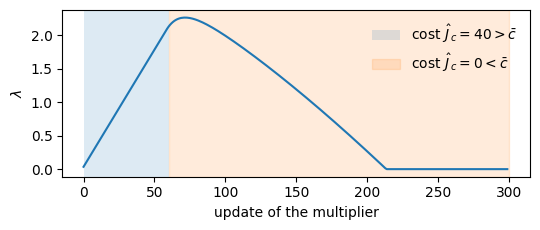

In [61]:
import matplotlib.pyplot as plt

multiplier = torch.zeros(1, requires_grad=True)
adam = torch.optim.Adam([multiplier], lr=TrainConfig.lagrangian_lr)
trace = []
for k in range(300):
    episodic_cost = 40.0 if k < 60 else 0.0
    _update_lagrange_multiplier(multiplier, adam, episodic_cost, COST_LIMIT)
    trace.append(float(multiplier))

fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.plot(trace)
ax.axvspan(0, 60, alpha=0.15, label=r"cost $\hat J_c=40>\bar c$")
ax.axvspan(60, 300, alpha=0.15, color="tab:orange", label=r"cost $\hat J_c=0<\bar c$")
ax.set_xlabel("update of the multiplier")
ax.set_ylabel(r"$\lambda$")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

**A tiny training run.** DMDP-Lag (SAC) is trained for 4000 steps and written to a temporary folder in the layout of `results/`.
The settings give 4000 environment steps in 2 environments, with uniformly random actions for the first 500 steps and one gradient step per environment step afterwards; the first episodes end after 2000 environment steps.
The log has one row each time episodes have been completed: the mean over the most recent training episodes of the return $R$ of the training reward without $-\beta\,\mathbb{D}_t$ (`ep_return`), of the benchmark return (`ep_task_return`), the cost, the dissimilarity, the fraction of steps within $\mathbb{D}_{\mathsf{thr}}$, the pitch, and the fraction of flipped steps, together with the multiplier and the temperature $\alpha$.

In [62]:
import shutil
import tempfile

demo_root = tempfile.mkdtemp()
demo = make_config("HalfCheetah", "DMDP-Lag", seed=0, learner=LEARNER,
                   total_steps=4000, num_envs=2, sac_hidden=64, sac_batch_size=64,
                   sac_learning_starts=500, sac_lambda_interval=500)
demo_dir = run_dir(demo_root, demo.env, demo.method, demo.seed)
log = pd.DataFrame(train_sac(demo, demo_dir, verbose=False))
print("files of the run:", sorted(os.listdir(demo_dir)))
log.drop(columns="seconds").round(3)

files of the run: ['config.json', 'episodes.csv', 'policy.pt', 'training.csv']


,step,ep_return,ep_task_return,ep_cost,ep_dissimilarity,ep_dissimilarity_median,ep_within,ep_pitch,ep_flipped,ep_length,lagrange_multiplier,alpha
0,2000,-291.769,-291.769,0.0,8.017,7.899,0.0,0.281,0.006,1000.0,0.0,0.629
1,4000,-331.578,-331.578,0.0,9.278,8.532,0.0,0.609,0.145,1000.0,0.0,0.344


**Evaluation of the tiny run.** `evaluate_policy` runs 8 episodes at each of two noise levels and stores `evaluation.npz`, `load_evaluation` reads it back as `{noise level: {name: array}}`, and `summarize_run` computes one row per noise level, as for the stored runs in Section 11.
The columns are the returns $R$, $r^{\mathsf{b}}$, and $r^{\mathsf{eva}}$, the cost, the stability distances `D_early` and `D_late`, the target distance `D_target`, the fraction `within` of steps with $\mathbb{D}_t\leq\mathbb{D}_{\mathsf{thr}}$, and the fraction `flipped` of steps with a flipped torso.

In [63]:
evaluate_policy(os.path.join(demo_dir, "policy.pt"), (0.0, 0.3), episodes=8, out_path=os.path.join(demo_dir, "evaluation.npz"))
rows, curves = summarize_run(load_evaluation(demo_root, demo.env, demo.method, demo.seed), load_config(demo_root, demo.env, demo.method, demo.seed))
shutil.rmtree(demo_root)
pd.DataFrame(rows).set_index("nu")[["ret", "ret_benchmark", "ret_eva", "cost", "D_early", "D_late", "D_target", "within", "flipped"]].round(3)

,ret,ret_benchmark,ret_eva,cost,D_early,D_late,D_target,within,flipped
nu,,,,,,,,,
0.0,-3.316,-3.316,-3.316,0.0,0.009,0.000,2.648,0.0,0.0
0.3,-3.483,-3.483,-3.483,0.0,0.020,0.013,2.648,0.0,0.0


## 11 Stored results (`results/sac`)

The folder `results/sac/HalfCheetah/<method>/seed<s>/` holds the eight methods of the SAC study with five seeds each: `config.json`, `training.csv`, `episodes.csv`, `policy.pt`, and `evaluation.npz`.
The command

```bash
python run_all.py --learner sac --methods SAC SAC-Lag Dist-SAC Dist-SAC-Lag Implicit-SAC Implicit-SAC-Lag DMDP DMDP-Lag --tag sac --workers 20
```

runs the following for every method and seed, with `--workers` runs in parallel (`run_one` in `run_all.py`):

```python
cfg = make_config("HalfCheetah", method, seed, learner="sac")   # 1 million steps per run
train_sac(cfg, out)                                             # out: results/sac/HalfCheetah/<method>/seed<seed>
evaluate_policy(os.path.join(out, "policy.pt"), EVAL_NOISES, EVAL_EPISODES, os.path.join(out, "evaluation.npz"))
```

A run whose `policy.pt` exists is not trained again, and noise levels that `evaluation.npz` already holds are not evaluated again.
The tables below are computed from the stored files with the functions of Section 9, and the tables of Section 5.1 come from the same functions.
Values are the mean $\pm$ the standard error over the five seeds, and the rows follow the order of the tables of the paper.
`evaluation.npz` has about 11 MB per run and is not kept in the repository, where `run_all.py` writes it again from `policy.pt`; without it, the notebook shows the training logs only.

In [64]:
from IPython.display import display

RESULTS = os.path.join("results", "sac")


def summary_table(frame, columns):
    """Mean ± standard error over the seeds of the columns, for the methods of ALL_METHODS, in this order."""
    index, rows = [], []
    for method in ALL_METHODS:
        runs = frame[frame["method"] == method]
        if len(runs):
            index.append(method_label(method, LEARNER))
            rows.append({header: f"{runs[column].mean():.{digits}f} ± {runs[column].sem():.{digits}f}"
                         for column, (header, digits) in columns.items()})
    return pd.DataFrame(rows, index=pd.Index(index, name="method"))

**Training logs.** The last row of `training.csv` of every run is the mean over the most recent training episodes at the end of training, with the stochastic policy and the noise level $\eta\sim U[0,0.3]$ of training.
The return $R$ is that of the reward the method is trained on, without $-\beta\,\mathbb{D}_t$ and $-\lambda c_t$, and $r^{\mathsf{b}}$ is the benchmark return.
The columns are the cost, the mean window dissimilarity $\mathbb{D}$ per step, and the fraction of steps with a flipped torso.

In [65]:
TRAIN_COLUMNS = {"ep_return": ("return R", 0), "ep_task_return": ("return r^b", 0), "ep_cost": ("cost", 1),
                 "ep_dissimilarity": ("D", 2), "ep_flipped": ("flipped", 2)}
finals = []
for method in ALL_METHODS:
    for seed in SEEDS:
        log = load_training(RESULTS, "HalfCheetah", method, seed)
        if log is not None:
            finals.append(dict(method=method, seed=seed, **log.iloc[-1][list(TRAIN_COLUMNS)]))
summary_table(pd.DataFrame(finals), TRAIN_COLUMNS) if finals else print("no stored runs found in", RESULTS)

,return R,return r^b,cost,D,flipped
method,,,,,
SAC,1633 ± 399,1633 ± 399,169.8 ± 122.9,5.62 ± 2.15,0.40 ± 0.23
SAC-Lag,1413 ± 232,1413 ± 232,4.1 ± 2.4,5.26 ± 2.39,0.41 ± 0.24
Distributional SAC,1325 ± 175,1325 ± 175,62.7 ± 20.7,7.11 ± 2.31,0.60 ± 0.23
Distributional SAC-Lag,1166 ± 102,1166 ± 102,6.5 ± 2.8,8.39 ± 1.87,0.72 ± 0.19
Implicit DMDP (SAC),3280 ± 183,3280 ± 183,663.4 ± 74.8,2.32 ± 0.31,0.00 ± 0.00
Implicit DMDP-Lag (SAC),2265 ± 127,2265 ± 127,7.4 ± 4.1,0.27 ± 0.10,0.00 ± 0.00
DMDP (SAC),6296 ± 2134,2631 ± 136,281.6 ± 108.8,0.70 ± 0.24,0.00 ± 0.00
DMDP-Lag (SAC),10689 ± 852,2219 ± 79,6.6 ± 2.5,0.22 ± 0.08,0.00 ± 0.00


**Evaluation.** `summarize_run` is applied to the stored evaluation of every run at the noise levels $\eta=0$ and $\eta=0.2$ (64 episodes per run).
The columns are the return of the evaluation reward $r^{\mathsf{eva}}_t$ (Section 9), the episodic cost, the stability distance $\mathbb{D}(\rho_k\|\hat\rho)$ averaged over $k<200$ and over $k\geq500$, the distance $\mathbb{D}(\hat\rho\|\rho^{v}_\star)$ of the stable velocity distribution to the target, and the fraction of steps with $\mathbb{D}_t\leq\mathbb{D}_{\mathsf{thr}}$.

In [66]:
EVAL_COLUMNS = {"ret_eva": ("return r^eva", 0), "cost": ("cost", 1),
                "D_early": ("D(ρ_k‖ρ̂), k<200", 3), "D_late": ("D(ρ_k‖ρ̂), k≥500", 3), "D_target": ("D(ρ̂‖ρ⋆)", 3),
                "within": ("P[D ≤ D_thr]", 2)}
rows = []
for method in ALL_METHODS:
    for seed in SEEDS:
        stored_evaluation = load_evaluation(RESULTS, "HalfCheetah", method, seed)
        if stored_evaluation is None:
            continue
        stored_evaluation = {nu: record for nu, record in stored_evaluation.items() if nu in (0.0, 0.2)}
        for row in summarize_run(stored_evaluation, load_config(RESULTS, "HalfCheetah", method, seed))[0]:
            rows.append(dict(row, method=method, seed=seed))
evaluated = pd.DataFrame(rows)
if evaluated.empty:
    print("no evaluation.npz found in", RESULTS, "- run_all.py writes it")
else:
    for nu in (0.0, 0.2):
        print(f"noise level eta = {nu}")
        display(summary_table(evaluated[evaluated["nu"] == nu], EVAL_COLUMNS))

noise level eta = 0.0


,return r^eva,cost,"D(ρ_k‖ρ̂), k<200","D(ρ_k‖ρ̂), k≥500",D(ρ̂‖ρ⋆),P[D ≤ D_thr]
method,,,,,,
SAC,461 ± 565,218.9 ± 126.1,0.470 ± 0.076,0.301 ± 0.065,0.982 ± 0.167,0.01 ± 0.01
SAC-Lag,3802 ± 1920,6.8 ± 3.7,0.261 ± 0.018,0.155 ± 0.022,0.728 ± 0.229,0.23 ± 0.17
Distributional SAC,819 ± 141,108.7 ± 48.7,0.362 ± 0.044,0.233 ± 0.026,0.962 ± 0.139,0.00 ± 0.00
Distributional SAC-Lag,1248 ± 85,11.2 ± 6.6,0.407 ± 0.056,0.247 ± 0.023,1.039 ± 0.121,0.00 ± 0.00
Implicit DMDP (SAC),-2410 ± 243,844.6 ± 46.6,1.028 ± 0.101,0.563 ± 0.171,1.876 ± 0.128,0.00 ± 0.00
Implicit DMDP-Lag (SAC),4729 ± 1346,2.2 ± 1.7,0.215 ± 0.009,0.061 ± 0.018,0.295 ± 0.033,0.22 ± 0.14
DMDP (SAC),4010 ± 3325,406.1 ± 166.9,0.661 ± 0.190,0.446 ± 0.176,0.810 ± 0.268,0.40 ± 0.24
DMDP-Lag (SAC),11981 ± 105,1.0 ± 0.5,0.205 ± 0.009,0.056 ± 0.006,0.132 ± 0.009,0.99 ± 0.01


noise level eta = 0.2


,return r^eva,cost,"D(ρ_k‖ρ̂), k<200","D(ρ_k‖ρ̂), k≥500",D(ρ̂‖ρ⋆),P[D ≤ D_thr]
method,,,,,,
SAC,526 ± 616,205.4 ± 130.0,0.368 ± 0.074,0.197 ± 0.021,1.063 ± 0.170,0.02 ± 0.02
SAC-Lag,3467 ± 1929,4.9 ± 2.2,0.256 ± 0.028,0.155 ± 0.033,0.814 ± 0.237,0.21 ± 0.18
Distributional SAC,837 ± 103,85.9 ± 35.3,0.334 ± 0.030,0.205 ± 0.018,1.034 ± 0.130,0.00 ± 0.00
Distributional SAC-Lag,1185 ± 95,7.8 ± 3.1,0.366 ± 0.039,0.205 ± 0.011,1.124 ± 0.104,0.00 ± 0.00
Implicit DMDP (SAC),-1824 ± 329,726.4 ± 63.2,0.816 ± 0.089,0.427 ± 0.136,1.460 ± 0.174,0.00 ± 0.00
Implicit DMDP-Lag (SAC),8824 ± 1758,9.2 ± 4.8,0.218 ± 0.009,0.073 ± 0.020,0.208 ± 0.073,0.68 ± 0.17
DMDP (SAC),4138 ± 2980,329.5 ± 132.4,0.568 ± 0.142,0.311 ± 0.107,0.627 ± 0.219,0.38 ± 0.23
DMDP-Lag (SAC),10617 ± 1191,6.3 ± 3.8,0.220 ± 0.020,0.062 ± 0.020,0.144 ± 0.051,0.87 ± 0.11
